In [1]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for f in filenames:
        print(os.path.join(dirname, f))

/kaggle/input/datasets/nooriasafdar/recsys-dataa/seller_offers.csv
/kaggle/input/datasets/nooriasafdar/recsys-dataa/products.csv
/kaggle/input/datasets/nooriasafdar/recsys-dataa/users.csv
/kaggle/input/datasets/nooriasafdar/recsys-dataa/README.md
/kaggle/input/datasets/nooriasafdar/recsys-dataa/recommendation_dataset/dataset/seller_offers.csv
/kaggle/input/datasets/nooriasafdar/recsys-dataa/recommendation_dataset/dataset/products.csv
/kaggle/input/datasets/nooriasafdar/recsys-dataa/recommendation_dataset/dataset/build_dataset.py
/kaggle/input/datasets/nooriasafdar/recsys-dataa/recommendation_dataset/dataset/users.csv
/kaggle/input/datasets/nooriasafdar/recsys-dataa/recommendation_dataset/dataset/README.md
/kaggle/input/datasets/nooriasafdar/recsys-dataa/recommendation_dataset/dataset/cleaning_report.csv
/kaggle/input/datasets/nooriasafdar/recsys-dataa/recommendation_dataset/dataset/sellers.csv
/kaggle/input/datasets/nooriasafdar/recsys-dataa/recommendation_dataset/dataset/events.csv


In [2]:
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# events.csv khud dhoondo (sab se chhota path = main folder wali file)
found = glob.glob('/kaggle/input/**/events.csv', recursive=True)
print(found)
BASE = min(found, key=len).replace('/events.csv', '')
print("BASE =", BASE)

events   = pd.read_csv(f'{BASE}/events.csv', parse_dates=['event_time'])
products = pd.read_csv(f'{BASE}/products.csv')
users    = pd.read_csv(f'{BASE}/users.csv')
offers   = pd.read_csv(f'{BASE}/seller_offers.csv')

for name, d in [('events', events), ('products', products), ('users', users), ('offers', offers)]:
    print(name, d.shape)

events.head()

['/kaggle/input/datasets/nooriasafdar/recsys-dataa/recommendation_dataset/dataset/events.csv']
BASE = /kaggle/input/datasets/nooriasafdar/recsys-dataa/recommendation_dataset/dataset
events (90244, 6)
products (1885, 10)
users (3750, 3)
offers (7451, 12)


,event_time,event_type,user_id,product_id,user_session,source
0,2019-12-01 00:00:18+00:00,cart,579966747,5629988,1512be50-d0fd-4a92-bcd8-3ea3943f2a3b,real
1,2019-12-01 00:00:46+00:00,view,579966747,5798929,1512be50-d0fd-4a92-bcd8-3ea3943f2a3b,real
2,2019-12-01 00:01:55+00:00,view,990000531,9000117,syn-990000531-0,synthetic
3,2019-12-01 00:02:34+00:00,cart,579966747,5798924,1512be50-d0fd-4a92-bcd8-3ea3943f2a3b,real
4,2019-12-01 00:02:41+00:00,view,579966747,5798929,1512be50-d0fd-4a92-bcd8-3ea3943f2a3b,real


In [3]:
events.info()
print(events.isna().sum())
print(events['event_type'].value_counts())
print(events['source'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90244 entries, 0 to 90243
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype              
---  ------        --------------  -----              
 0   event_time    90244 non-null  datetime64[ns, UTC]
 1   event_type    90244 non-null  object             
 2   user_id       90244 non-null  int64              
 3   product_id    90244 non-null  int64              
 4   user_session  90244 non-null  object             
 5   source        90244 non-null  object             
dtypes: datetime64[ns, UTC](1), int64(2), object(3)
memory usage: 4.1+ MB
event_time      0
event_type      0
user_id         0
product_id      0
user_session    0
source          0
dtype: int64
event_type
view                42754
cart                27056
remove_from_cart    12337
purchase             8097
Name: count, dtype: int64
source
real         70409
synthetic    19835
Name: count, dtype: int64


In [4]:
for name, d in [('events', events), ('products', products), ('users', users), ('offers', offers)]:
    print(f"\n=== {name}: {d.shape[0]} rows, {d.shape[1]} columns ===")
    print(list(d.columns))


=== events: 90244 rows, 6 columns ===
['event_time', 'event_type', 'user_id', 'product_id', 'user_session', 'source']

=== products: 1885 rows, 10 columns ===
['product_id', 'product_name', 'brand', 'main_category', 'price', 'price_pkr', 'avg_rating', 'review_count', 'category_id', 'source']

=== users: 3750 rows, 3 columns ===
['user_id', 'user_label', 'source']

=== offers: 7451 rows, 12 columns ===
['product_id', 'seller_id', 'price', 'shipping', 'total_cost', 'price_pkr', 'shipping_pkr', 'total_cost_pkr', 'rating', 'review_count', 'stock', 'quality']


In [5]:
display(events.head())
display(events.tail())
display(events.describe(include='all').T)
print(events.nunique())

,event_time,event_type,user_id,product_id,user_session,source
0,2019-12-01 00:00:18+00:00,cart,579966747,5629988,1512be50-d0fd-4a92-bcd8-3ea3943f2a3b,real
1,2019-12-01 00:00:46+00:00,view,579966747,5798929,1512be50-d0fd-4a92-bcd8-3ea3943f2a3b,real
2,2019-12-01 00:01:55+00:00,view,990000531,9000117,syn-990000531-0,synthetic
3,2019-12-01 00:02:34+00:00,cart,579966747,5798924,1512be50-d0fd-4a92-bcd8-3ea3943f2a3b,real
4,2019-12-01 00:02:41+00:00,view,579966747,5798929,1512be50-d0fd-4a92-bcd8-3ea3943f2a3b,real


,event_time,event_type,user_id,product_id,user_session,source
90239,2019-12-31 23:56:39+00:00,view,502631750,5622677,6edb4c0e-285c-4fbc-8977-589ef6d326b8,real
90240,2019-12-31 23:58:35+00:00,cart,502631750,5622677,6edb4c0e-285c-4fbc-8977-589ef6d326b8,real
90241,2019-12-31 23:58:55+00:00,view,502631750,5549834,6edb4c0e-285c-4fbc-8977-589ef6d326b8,real
90242,2020-01-01 00:13:40+00:00,cart,990000650,9000100,syn-990000650-30,synthetic
90243,2020-01-01 00:26:40+00:00,remove_from_cart,990000650,9000100,syn-990000650-30,synthetic


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
event_time,90244,NaN,NaN,NaN,2019-12-15 08:08:28.314203648+00:00,2019-12-01 00:00:18+00:00,2019-12-08 10:36:56.750000128+00:00,2019-12-14 19:03:07.500000+00:00,2019-12-22 12:37:27.249999872+00:00,2020-01-01 00:26:40+00:00,NaN
event_type,90244,4,view,42754,NaN,NaN,NaN,NaN,NaN,NaN,NaN
user_id,90244.0,NaN,NaN,NaN,625298289.565755,51824526.0,508907094.0,574720017.0,591948175.0,990000800.0,206131273.720533
product_id,90244.0,NaN,NaN,NaN,6107390.331834,3762.0,5739055.0,5820752.0,5894906.0,9000200.0,1954849.518054
user_session,90244,23175,ce626646-ab86-4478-a56d-5d7511e628da,178,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source,90244,2,real,70409,NaN,NaN,NaN,NaN,NaN,NaN,NaN


event_time      83504
event_type          4
user_id          3750
product_id       1885
user_session    23175
source              2
dtype: int64


In [6]:
events.isna().sum().sum()

np.int64(0)

In [7]:
display(products.head())
display(products.describe(include='all').T)

,product_id,product_name,brand,main_category,price,price_pkr,avg_rating,review_count,category_id,source
0,3762,CND Nail Product #3762,cnd,Nail Care,19.37,5424,4.4,450,1.487580e+18,real
1,3978,CND Nail Product #3978,cnd,Nail Care,29.05,8134,4.2,951,1.487580e+18,real
2,4185,CND Nail Product #4185,cnd,Nail Care,19.37,5424,4.7,767,1.487580e+18,real
3,4229,CND Nail Product #4229,cnd,Nail Care,29.05,8134,4.5,849,1.487580e+18,real
4,4497,Runail Nail Product #4497,runail,Nail Care,3.11,871,4.4,874,2.195085e+18,real


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
product_id,1885.0,NaN,NaN,NaN,5750525.864191,1804648.797402,3762.0,5705014.0,5810672.0,5869143.0,9000200.0
product_name,1885,1853,Generic Beauty Product #4897,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
brand,1885,113,unknown,775,NaN,NaN,NaN,NaN,NaN,NaN,NaN
main_category,1885,10,Beauty & Salon Supplies,941,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,1885.0,NaN,NaN,NaN,12.054212,27.277822,0.08,1.98,4.21,7.78,385.3
price_pkr,1885.0,NaN,NaN,NaN,3375.184615,7637.796595,22.0,554.0,1179.0,2178.0,107884.0
avg_rating,1885.0,NaN,NaN,NaN,4.349019,0.205821,3.7,4.2,4.4,4.5,5.0
review_count,1885.0,NaN,NaN,NaN,804.467905,274.336367,126.0,613.0,784.0,973.0,1782.0
category_id,1685.0,NaN,NaN,NaN,1552928990427305984.0,174623739189266048.0,1487580004857414400.0,1487580005754995712.0,1487580008028308480.0,1487580012969197824.0,2235524494015856896.0
source,1885,2,real,1685,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
# --- products cleanup ---
products = products.drop(columns=['category_id'], errors='ignore')   # float precision issue, zaroorat nahi
products['brand_clean'] = products['brand'].replace('unknown', np.nan)  # unknown = missing
products['is_branded']  = products['brand_clean'].notna()

# --- merge and add new columns ---
events['event_time'] = pd.to_datetime(events['event_time'], utc=True)

df = events.merge(
    products[['product_id', 'product_name', 'brand', 'brand_clean', 'is_branded',
              'main_category', 'price', 'price_pkr']],
    on='product_id', how='left')

df['date'] = df['event_time'].dt.date
df['hour'] = df['event_time'].dt.hour
df['weekday'] = df['event_time'].dt.day_name()
df['is_weekend'] = df['event_time'].dt.dayofweek >= 5

df = df.sort_values(['user_id', 'event_time']).reset_index(drop=True)
print(df.shape, '| branded events: %.1f%%' % (df.is_branded.mean() * 100))
df.head()

(90244, 17) | branded events: 65.4%


,event_time,event_type,user_id,product_id,user_session,source,product_name,brand,brand_clean,is_branded,main_category,price,price_pkr,date,hour,weekday,is_weekend
0,2019-12-03 05:57:04+00:00,view,51824526,5650457,c24778fb-fb85-40f9-910b-0c15896bc58c,real,Metzger Beauty Product #0457,metzger,metzger,True,Beauty & Salon Supplies,6.83,1912,2019-12-03,5,Tuesday,False
1,2019-12-03 05:58:30+00:00,view,51824526,5650457,c24778fb-fb85-40f9-910b-0c15896bc58c,real,Metzger Beauty Product #0457,metzger,metzger,True,Beauty & Salon Supplies,6.83,1912,2019-12-03,5,Tuesday,False
2,2019-12-03 06:07:45+00:00,view,51824526,5885848,c24778fb-fb85-40f9-910b-0c15896bc58c,real,Generic Beauty Product #5848,unknown,NaN,False,Beauty & Salon Supplies,7.22,2022,2019-12-03,6,Tuesday,False
3,2019-12-03 06:08:31+00:00,view,51824526,5650457,c24778fb-fb85-40f9-910b-0c15896bc58c,real,Metzger Beauty Product #0457,metzger,metzger,True,Beauty & Salon Supplies,6.83,1912,2019-12-03,6,Tuesday,False
4,2019-12-03 06:25:33+00:00,cart,51824526,5650457,c24778fb-fb85-40f9-910b-0c15896bc58c,real,Metzger Beauty Product #0457,metzger,metzger,True,Beauty & Salon Supplies,6.83,1912,2019-12-03,6,Tuesday,False


In [9]:
# cleaning
print(df.isna().sum())
print('Duplicates:', df.duplicated().sum())
print('Price <= 0:', (df['price'] <= 0).sum())
print('Invalid event types:',
      (~df['event_type'].isin(['view', 'cart', 'remove_from_cart', 'purchase'])).sum())
print('Time range:', df['event_time'].min(), '->', df['event_time'].max())
print('Synthetic ID mismatch:',
      ((df['source'] == 'synthetic') != (df['user_id'] >= 990000001)).sum())

event_time           0
event_type           0
user_id              0
product_id           0
user_session         0
source               0
product_name         0
brand                0
brand_clean      31237
is_branded           0
main_category        0
price                0
price_pkr            0
date                 0
hour                 0
weekday              0
is_weekend           0
dtype: int64
Duplicates: 0
Price <= 0: 0
Invalid event types: 0
Time range: 2019-12-01 00:00:18+00:00 -> 2020-01-01 00:26:40+00:00
Synthetic ID mismatch: 0


IQR upper limit: 56.5 | users above it: 302 | max events: 300


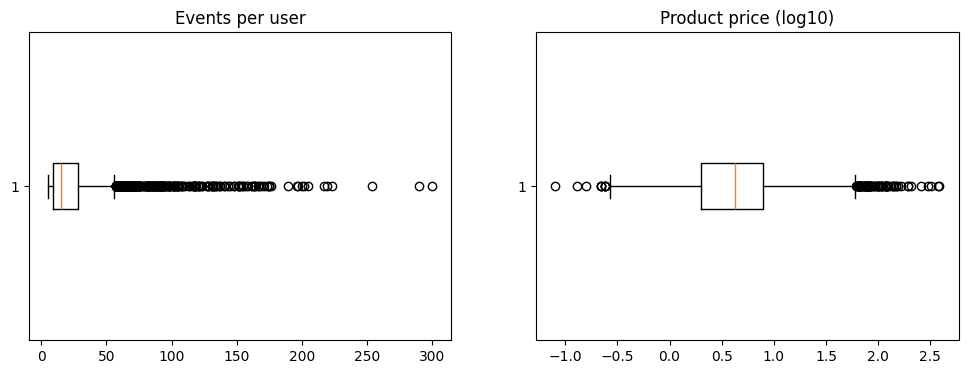

In [10]:
user_ev = df.groupby('user_id').size()
q1, q3 = user_ev.quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print('IQR upper limit:', upper, '| users above it:', (user_ev > upper).sum(), '| max events:', user_ev.max())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].boxplot(user_ev, vert=False); ax[0].set_title('Events per user')
ax[1].boxplot(np.log10(products['price']), vert=False); ax[1].set_title('Product price (log10)')
plt.show()

In [11]:
# EDA
from scipy import stats
import statsmodels.api as sm
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler

ue = df.pivot_table(index='user_id', columns='event_type', values='product_id',
                    aggfunc='count', fill_value=0)
ue['total_events'] = ue.sum(axis=1)
ue['unique_products'] = df.groupby('user_id')['product_id'].nunique()
ue['avg_price'] = df.groupby('user_id')['price'].mean()
ue['source'] = df.groupby('user_id')['source'].first()

num = ['view', 'cart', 'purchase', 'total_events', 'unique_products', 'avg_price']
print(ue.shape)


(3750, 8)


           feature  skew  kurtosis     shapiro_p
0             view  3.74     23.09  4.796704e-65
1             cart  4.22     27.83  1.880138e-67
2         purchase  3.60     22.68  1.049463e-67
3     total_events  3.57     18.61  9.844924e-67
4  unique_products  2.97     14.10  6.170213e-61
5        avg_price  2.55      8.22  5.325454e-66


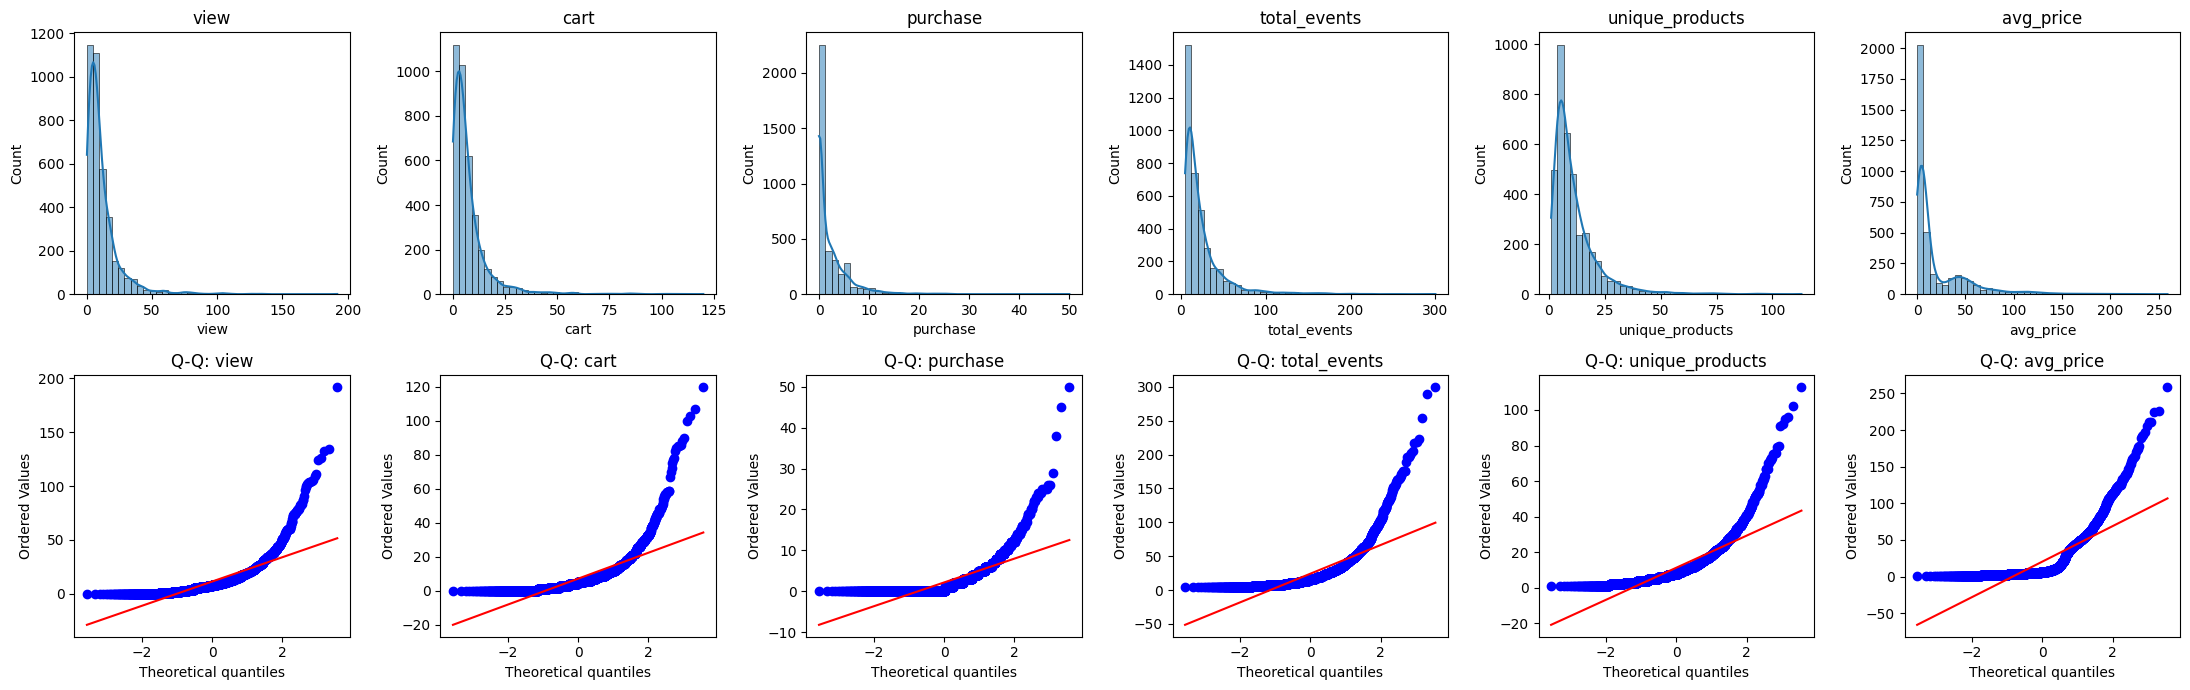

In [12]:
rows = []
for c in num:
    x = ue[c]
    s = x.sample(min(5000, len(x)), random_state=42)
    rows.append([c, round(x.skew(), 2), round(stats.kurtosis(x), 2), stats.shapiro(s)[1]])
print(pd.DataFrame(rows, columns=['feature', 'skew', 'kurtosis', 'shapiro_p']))

fig, ax = plt.subplots(2, 6, figsize=(22, 7))
for i, c in enumerate(num):
    sns.histplot(ue[c], bins=40, kde=True, ax=ax[0, i]); ax[0, i].set_title(c)
    stats.probplot(ue[c], dist='norm', plot=ax[1, i]); ax[1, i].set_title(f'Q-Q: {c}')
plt.tight_layout(); plt.show()

                 before  after_log
event_type                        
view               3.74      -0.22
cart               4.22      -0.03
purchase           3.60       0.78
total_events       3.57       0.68
unique_products    2.97       0.20
avg_price          2.55       0.67


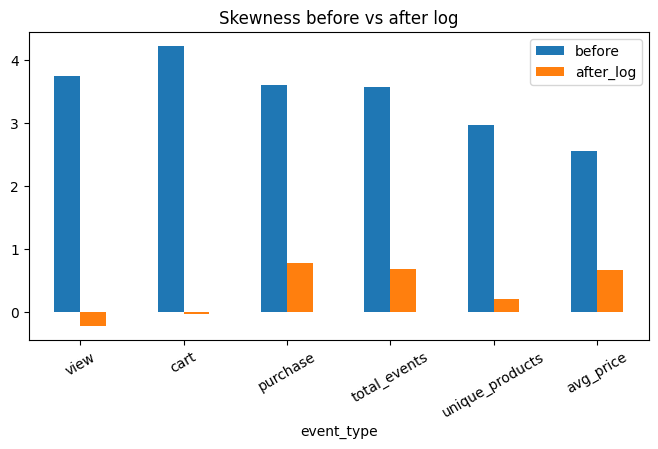

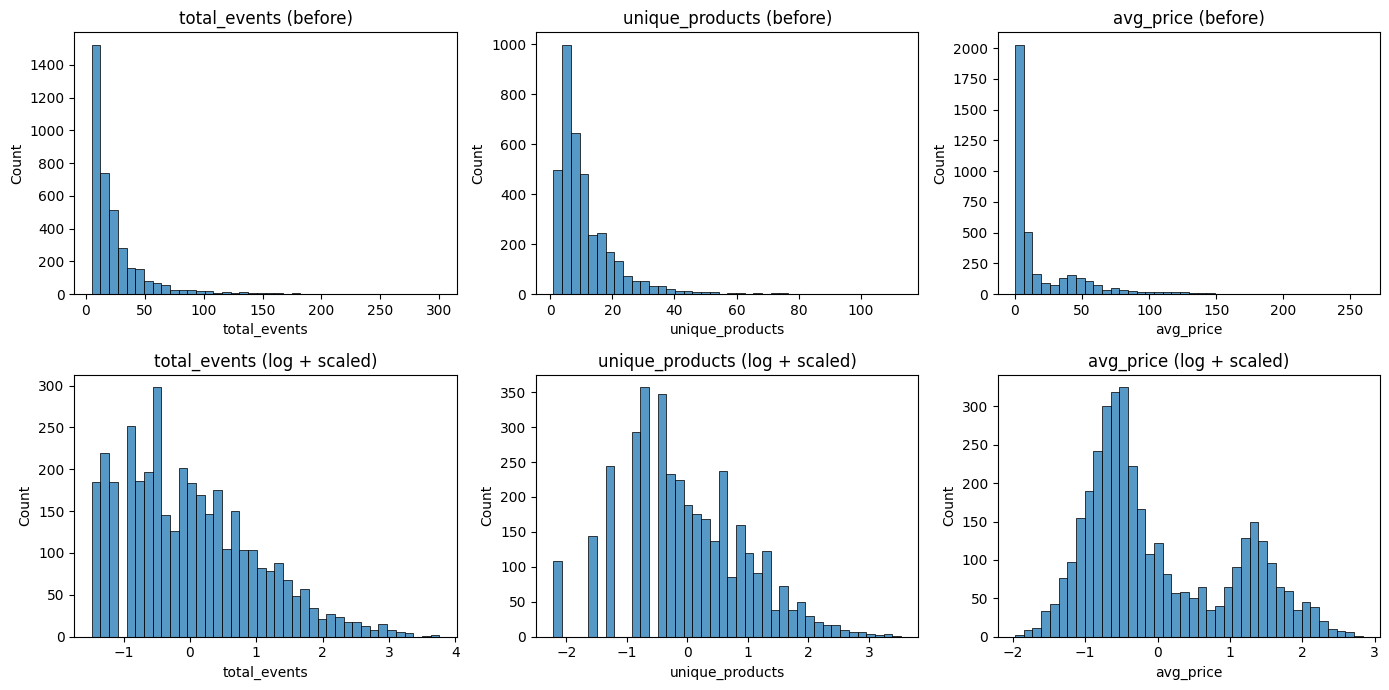

      view  cart  purchase  total_events  unique_products  avg_price
mean   0.0   0.0       0.0          -0.0             -0.0        0.0
std    1.0   1.0       1.0           1.0              1.0        1.0


In [13]:
# normalization
X = ue[num].copy()
X_log = np.log1p(X)
X_scaled = pd.DataFrame(StandardScaler().fit_transform(X_log), columns=num, index=X.index)

skew = pd.DataFrame({'before': X.skew(), 'after_log': X_log.skew()}).round(2)
print(skew)
skew.plot(kind='bar', figsize=(8, 4), title='Skewness before vs after log'); plt.xticks(rotation=30); plt.show()

fig, ax = plt.subplots(2, 3, figsize=(14, 7))
for i, c in enumerate(['total_events', 'unique_products', 'avg_price']):
    sns.histplot(X[c], bins=40, ax=ax[0, i]); ax[0, i].set_title(f'{c} (before)')
    sns.histplot(X_scaled[c], bins=40, ax=ax[1, i]); ax[1, i].set_title(f'{c} (log + scaled)')
plt.tight_layout(); plt.show()
print(X_scaled.describe().loc[['mean', 'std']].round(2))

                          pair    chi2  p_value  cramers_v
0  main_category vs event_type  3909.2      0.0      0.120
1         source vs event_type  4267.1      0.0      0.217


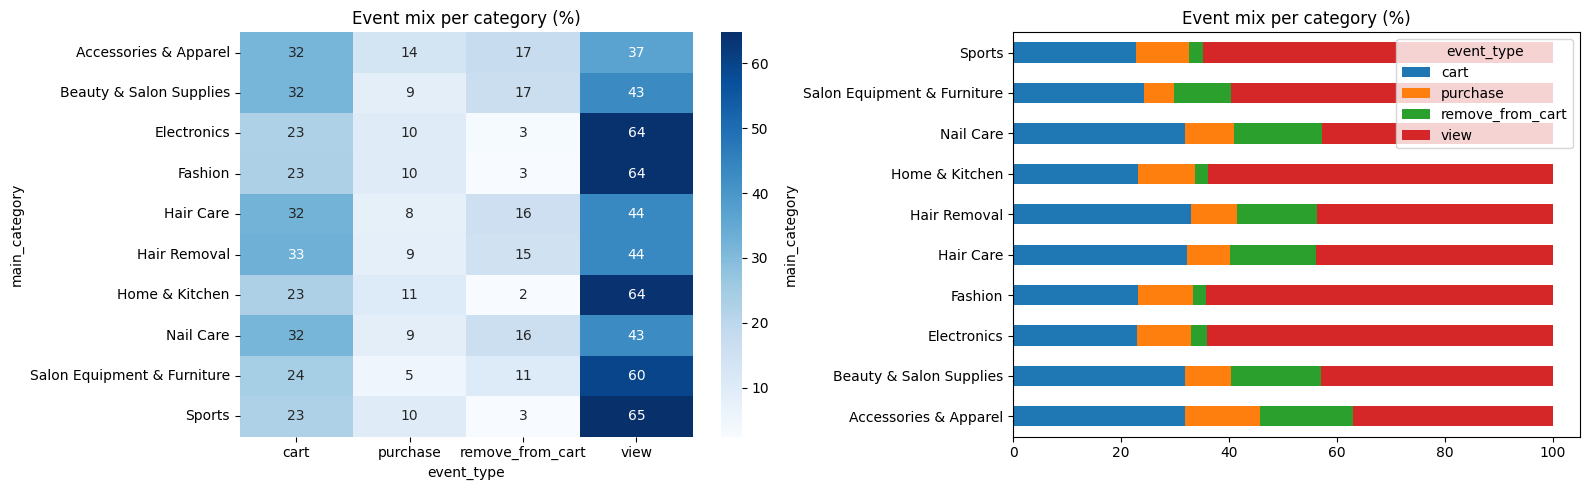

In [14]:
# independency
from scipy.stats import chi2_contingency

def cramers_v(ct):
    chi2 = chi2_contingency(ct)[0]
    return np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))

pairs = [('main_category', 'event_type'), ('source', 'event_type')]
res = []
for a, b in pairs:
    ct = pd.crosstab(df[a], df[b])
    chi2, p, dof, _ = chi2_contingency(ct)
    res.append([f'{a} vs {b}', round(chi2, 1), p, round(cramers_v(ct), 3)])
print(pd.DataFrame(res, columns=['pair', 'chi2', 'p_value', 'cramers_v']))

ct = pd.crosstab(df['main_category'], df['event_type'])
pct = ct.div(ct.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(pct, annot=True, fmt='.0f', cmap='Blues', ax=ax[0]); ax[0].set_title('Event mix per category (%)')
pct.plot(kind='barh', stacked=True, ax=ax[1], title='Event mix per category (%)')
plt.tight_layout(); plt.show()

           feature    VIF
0             view   3.79
1             cart   4.14
2         purchase   1.61
3     total_events  11.26
4  unique_products   3.59
5        avg_price   1.28


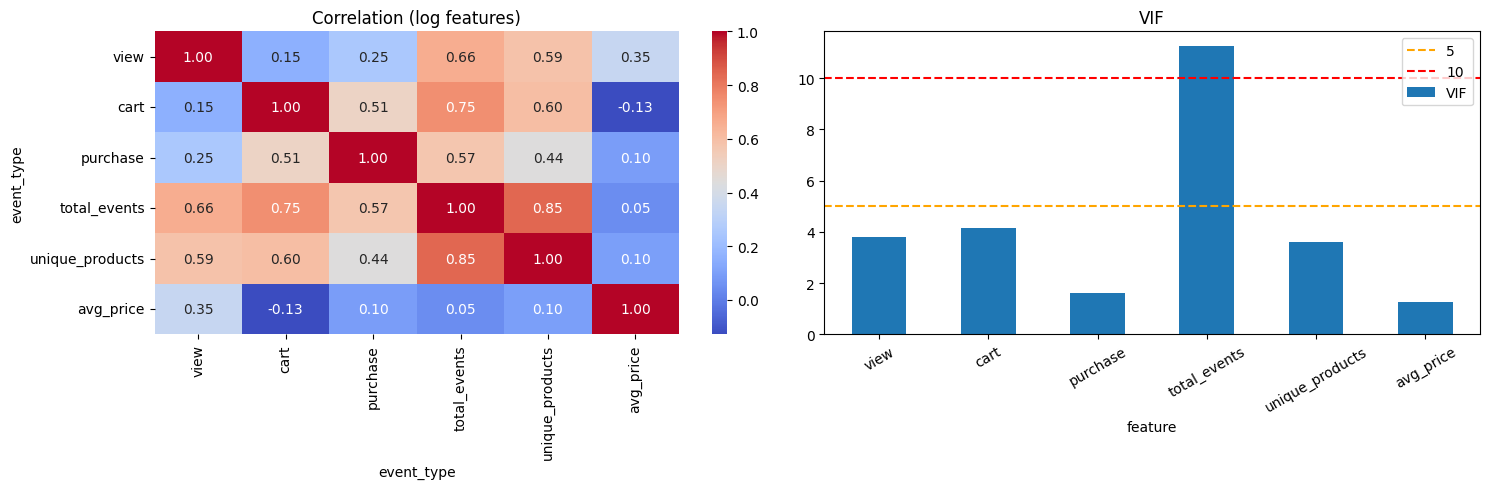

In [15]:
# multicollinearity
Xv = sm.add_constant(X_log)
vif = pd.DataFrame({'feature': X_log.columns,
                    'VIF': [variance_inflation_factor(Xv.values, i + 1) for i in range(X_log.shape[1])]})
print(vif.round(2))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(X_log.corr(), annot=True, cmap='coolwarm', fmt='.2f', ax=ax[0]); ax[0].set_title('Correlation (log features)')
vif.set_index('feature')['VIF'].plot(kind='bar', ax=ax[1], title='VIF')
ax[1].axhline(5, color='orange', ls='--', label='5'); ax[1].axhline(10, color='red', ls='--', label='10')
ax[1].legend(); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

           feature   VIF
0             view  1.86
1             cart  2.05
2         purchase  1.44
3  unique_products  2.60
4        avg_price  1.20


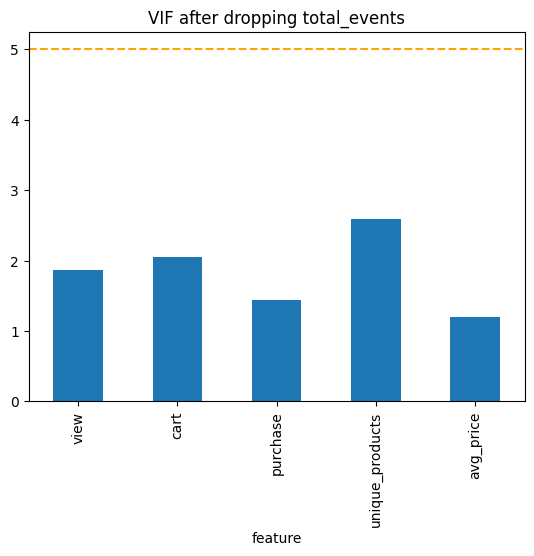

In [16]:
feat = ['view', 'cart', 'purchase', 'unique_products', 'avg_price']
Xv2 = sm.add_constant(X_log[feat])
vif2 = pd.DataFrame({'feature': feat,
                     'VIF': [variance_inflation_factor(Xv2.values, i + 1) for i in range(len(feat))]})
print(vif2.round(2))
vif2.set_index('feature')['VIF'].plot(kind='bar', title='VIF after dropping total_events')
plt.axhline(5, color='orange', ls='--'); plt.show()

Mean  real/syn: 23.9 24.8
Var   real/syn: 821.9 244.8
Levene (variance): LeveneResult(statistic=np.float64(19.834956018957676), pvalue=np.float64(8.688629004030724e-06))
Welch t-test (mean): TtestResult(statistic=np.float64(-1.2114641665945391), pvalue=np.float64(0.22583776325608693), df=np.float64(2381.293935951988))
Mann-Whitney: MannwhitneyuResult(statistic=np.float64(861426.5), pvalue=np.float64(8.204879956068655e-32))
ANOVA: F_onewayResult(statistic=np.float64(113.0141411946541), pvalue=np.float64(2.0036429439123125e-169))
Kruskal-Wallis: KruskalResult(statistic=np.float64(529.7750343298524), pvalue=np.float64(2.4079003744420005e-108))
Views buyer/non-buyer: 14.2 8.6 MannwhitneyuResult(statistic=np.float64(2212516.5), pvalue=np.float64(5.489891583494744e-43))


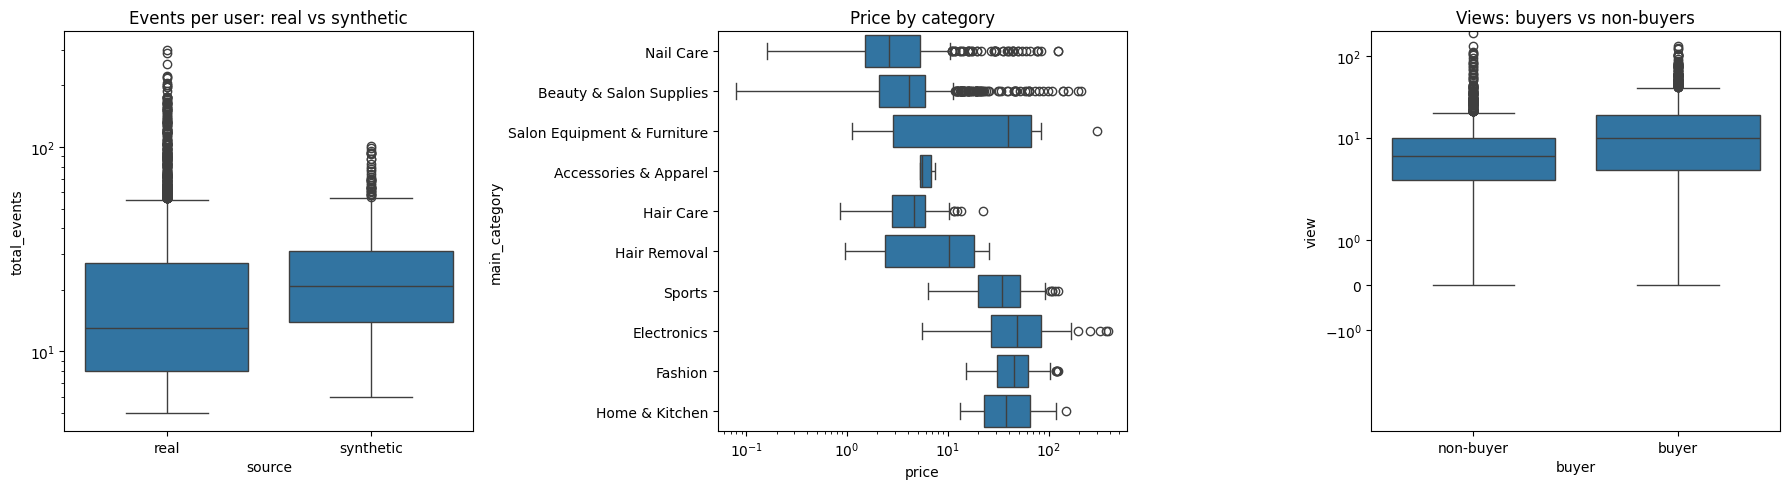

In [17]:
real = ue[ue.source == 'real']['total_events']
syn = ue[ue.source == 'synthetic']['total_events']
print('Mean  real/syn:', round(real.mean(), 1), round(syn.mean(), 1))
print('Var   real/syn:', round(real.var(), 1), round(syn.var(), 1))
print('Levene (variance):', stats.levene(real, syn))
print('Welch t-test (mean):', stats.ttest_ind(real, syn, equal_var=False))
print('Mann-Whitney:', stats.mannwhitneyu(real, syn))

groups = [g['price'].values for _, g in products.groupby('main_category')]
print('ANOVA:', stats.f_oneway(*groups))
print('Kruskal-Wallis:', stats.kruskal(*groups))

ue['buyer'] = np.where(ue['purchase'] > 0, 'buyer', 'non-buyer')
buy, nobuy = ue[ue.buyer == 'buyer']['view'], ue[ue.buyer == 'non-buyer']['view']
print('Views buyer/non-buyer:', round(buy.mean(), 1), round(nobuy.mean(), 1), stats.mannwhitneyu(buy, nobuy))

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=ue, x='source', y='total_events', ax=ax[0]); ax[0].set_yscale('log'); ax[0].set_title('Events per user: real vs synthetic')
sns.boxplot(data=products, y='main_category', x='price', ax=ax[1]); ax[1].set_xscale('log'); ax[1].set_title('Price by category')
sns.boxplot(data=ue, x='buyer', y='view', ax=ax[2]); ax[2].set_yscale('symlog'); ax[2].set_title('Views: buyers vs non-buyers')
plt.tight_layout(); plt.show()

In [18]:
# ---------- Time-based split (leakage-free) ----------
CUTOFF = pd.Timestamp('2019-12-20', tz='UTC')   # is se pehle = train, baad mein = test

train_t = df[df.event_time < CUTOFF].copy()
after   = df[df.event_time >= CUTOFF]

# test = cutoff ke baad ki purchases, jo user ne train mein pehle nahi khareedi thin
bought_before = (train_t[train_t.event_type == 'purchase'][['user_id', 'product_id']]
                 .drop_duplicates().assign(seen=1))
test_t = (after[after.event_type == 'purchase'][['user_id', 'product_id']]
          .drop_duplicates()
          .merge(bought_before, on=['user_id', 'product_id'], how='left'))
test_t = test_t[test_t.seen.isna()].drop(columns='seen')

test_t['is_warm'] = test_t.user_id.isin(set(train_t.user_id))   # True = train mein history hai
test_t['source']  = np.where(test_t.user_id >= 990000001, 'synthetic', 'real')

print('Train rows:', len(train_t), '| Test pairs:', len(test_t))
print(test_t.groupby(['source', 'is_warm']).user_id.nunique())
train = train_t


Train rows: 61041 | Test pairs: 2570
source     is_warm
real       False      234
           True       167
synthetic  True       456
Name: user_id, dtype: int64


In [19]:
g = train.groupby('user_id')
uf = train.pivot_table(index='user_id', columns='event_type', values='product_id',
                       aggfunc='count', fill_value=0)
for c in ['view', 'cart', 'remove_from_cart', 'purchase']:
    if c not in uf.columns:
        uf[c] = 0
uf['unique_products'] = g['product_id'].nunique()
uf['avg_price'] = g['price'].mean()
uf['cart_rate'] = uf['cart'] / (uf['view'] + 1)
uf['purchase_rate'] = uf['purchase'] / (uf['view'] + 1)
uf['active_days'] = g['event_time'].apply(lambda s: s.dt.date.nunique())
uf['recency_days'] = (train['event_time'].max() - g['event_time'].max()).dt.days
cat_share = pd.crosstab(train['user_id'], train['main_category'], normalize='index')

print(uf.shape, cat_share.shape)
uf.head()

(3103, 10) (3103, 10)


event_type,cart,purchase,remove_from_cart,view,unique_products,avg_price,cart_rate,purchase_rate,active_days,recency_days
user_id,,,,,,,,,,
51824526,4,0,2,15,9,4.471905,0.250000,0.000000,6,7
81128893,1,1,3,1,5,8.330000,0.500000,0.500000,2,3
93279832,4,3,3,13,11,2.221739,0.285714,0.214286,2,0
105379623,1,6,1,4,7,3.235000,0.200000,1.200000,1,9
112556049,6,1,0,1,2,1.250000,3.000000,0.500000,1,15


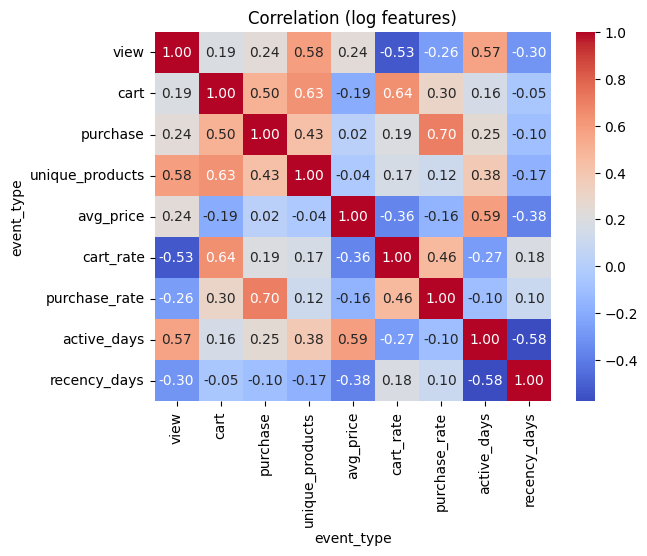

dropping cart_rate 8.98
Final features: ['view', 'cart', 'purchase', 'unique_products', 'avg_price', 'purchase_rate', 'active_days', 'recency_days']
view               2.87
cart               2.20
purchase           3.76
unique_products    2.80
avg_price          1.82
purchase_rate      3.40
active_days        2.87
recency_days       1.51
dtype: float64


In [20]:
behav = ['view', 'cart', 'purchase', 'unique_products', 'avg_price',
         'cart_rate', 'purchase_rate', 'active_days', 'recency_days']
Xb = np.log1p(uf[behav])

sns.heatmap(Xb.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation (log features)'); plt.show()

def drop_high_vif(Xd, thr=5):
    cols = list(Xd.columns)
    while True:
        Xc = sm.add_constant(Xd[cols])
        v = pd.Series([variance_inflation_factor(Xc.values, i + 1) for i in range(len(cols))], index=cols)
        if v.max() <= thr:
            return cols, v
        print('dropping', v.idxmax(), round(v.max(), 2))
        cols.remove(v.idxmax())

final_cols, vif_final = drop_high_vif(Xb)
print('Final features:', final_cols)
print(vif_final.round(2))

In [21]:
scaler = StandardScaler()
Xs = pd.DataFrame(scaler.fit_transform(np.log1p(uf[final_cols])),
                  index=uf.index, columns=final_cols)
X_cluster = pd.concat([Xs, cat_share.reindex(uf.index).fillna(0)], axis=1)
print(X_cluster.shape)
X_cluster.head()

(3103, 18)


,view,cart,purchase,unique_products,avg_price,purchase_rate,active_days,recency_days,Accessories & Apparel,Beauty & Salon Supplies,Electronics,Fashion,Hair Care,Hair Removal,Home & Kitchen,Nail Care,Salon Equipment & Furniture,Sports
user_id,,,,,,,,,,,,,,,,,,
51824526,0.951046,0.146494,-0.779935,0.309548,-0.616598,-0.511678,1.053160,0.595703,0.0,0.523810,0.0,0.0,0.0,0.0,0.0,0.476190,0.0,0.0
81128893,-1.312226,-0.817321,0.089416,-0.413338,-0.163124,0.612604,-0.341579,-0.124101,0.0,0.166667,0.0,0.0,0.0,0.0,0.0,0.833333,0.0,0.0
93279832,0.805710,0.146494,0.958766,0.567557,-1.066755,0.026681,-0.341579,-1.563708,0.0,0.086957,0.0,0.0,0.0,0.0,0.0,0.913043,0.0,0.0
105379623,-0.314932,-0.817321,1.660641,-0.006230,-0.834360,1.674573,-1.009016,0.827428,0.0,0.583333,0.0,0.0,0.0,0.0,0.0,0.416667,0.0,0.0
112556049,-1.312226,0.500418,0.089416,-1.394234,-1.371834,0.612604,-1.009016,1.315507,0.0,1.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0


In [22]:
pf = products[['product_id', 'product_name', 'brand', 'main_category', 'price', 'avg_rating']].copy()
pop = train.pivot_table(index='product_id', columns='event_type', values='user_id',
                        aggfunc='count', fill_value=0)
pf = pf.merge(pop, on='product_id', how='left').fillna(0)
pf['price_bucket'] = pd.qcut(pf['price'], 3, labels=['low', 'mid', 'high'])
print(pf.shape)
pf.head()

(1885, 11)


,product_id,product_name,brand,main_category,price,avg_rating,cart,purchase,remove_from_cart,view,price_bucket
0,3762,CND Nail Product #3762,cnd,Nail Care,19.37,4.4,10.0,6.0,2.0,24.0,high
1,3978,CND Nail Product #3978,cnd,Nail Care,29.05,4.2,3.0,0.0,3.0,14.0,high
2,4185,CND Nail Product #4185,cnd,Nail Care,19.37,4.7,13.0,5.0,2.0,31.0,high
3,4229,CND Nail Product #4229,cnd,Nail Care,29.05,4.5,5.0,2.0,4.0,16.0,high
4,4497,Runail Nail Product #4497,runail,Nail Care,3.11,4.4,21.0,5.0,10.0,28.0,mid


In [23]:
# ratings nai hain tw events ko numbers diye
RATING_W   = {'view': 1, 'cart': 1.5, 'purchase': 2, 'remove_from_cart': 0}
RATING_CAP = 2

tr = train.copy()
tr['w'] = tr['event_type'].map(RATING_W)

ratings = tr.groupby(['user_id', 'product_id'])['w'].sum().reset_index()
ratings = ratings[ratings['w'] > 0]
ratings['rating'] = ratings['w'].clip(upper=RATING_CAP)

print(ratings.shape)
print(ratings['rating'].describe().round(2))

(27980, 4)
count    27980.00
mean         1.52
std          0.45
min          1.00
25%          1.00
50%          1.50
75%          2.00
max          2.00
Name: rating, dtype: float64


In [24]:
from scipy.sparse import csr_matrix

user_ids = np.sort(ratings['user_id'].unique())
item_ids = np.sort(products['product_id'].unique())
u_idx = {u: i for i, u in enumerate(user_ids)}
i_idx = {p: i for i, p in enumerate(item_ids)}

R = csr_matrix((ratings['rating'].values,
                (ratings['user_id'].map(u_idx).values, ratings['product_id'].map(i_idx).values)),
               shape=(len(user_ids), len(item_ids)))

print('Matrix shape:', R.shape)
print('Filled cells:', R.nnz, '| Sparsity:', round(1 - R.nnz / (R.shape[0] * R.shape[1]), 4))

Matrix shape: (3085, 1885)
Filled cells: 27980 | Sparsity: 0.9952


In [25]:
# ===== B1: Validation split =====
VAL_CUT = pd.Timestamp('2019-12-13', tz='UTC')

train_core = train_t[train_t.event_time <  VAL_CUT].copy()   # 1-12 Dec
val_period = train_t[train_t.event_time >= VAL_CUT].copy()   # 13-19 Dec

def make_pairs(train_df, later_df):
    """later_df ki wo purchases jo user ne train_df mein pehle nahi khareedi thin"""
    bought = (train_df[train_df.event_type == 'purchase'][['user_id', 'product_id']]
              .drop_duplicates().assign(seen=1))
    p = (later_df[later_df.event_type == 'purchase'][['user_id', 'product_id']]
         .drop_duplicates()
         .merge(bought, on=['user_id', 'product_id'], how='left'))
    p = p[p.seen.isna()].drop(columns='seen')
    p['is_warm'] = p.user_id.isin(set(train_df.user_id))
    p['source']  = np.where(p.user_id >= 990000001, 'synthetic', 'real')
    return p

val_pairs = make_pairs(train_core, val_period)

# leakage check: train ka aakhri event validation ke pehle event se pehle ho
assert train_core.event_time.max() < val_period.event_time.min()
assert train_t.event_time.max() < CUTOFF

print('train_core :', len(train_core), 'rows |', train_core.event_time.min().date(), '->', train_core.event_time.max().date())
print('val_period :', len(val_period), 'rows |', val_period.event_time.min().date(), '->', val_period.event_time.max().date())
print('val_pairs  :', len(val_pairs))
print(val_pairs.groupby(['source', 'is_warm']).user_id.nunique())

chk = make_pairs(train_t, df[df.event_time >= CUTOFF])
print('test_t same as Part A?', len(chk) == len(test_t))   # True aana chahiye

train_core : 40468 rows | 2019-12-01 -> 2019-12-12
val_period : 20573 rows | 2019-12-13 -> 2019-12-19
val_pairs  : 1862
source     is_warm
real       False      162
           True       160
synthetic  False        2
           True       287
Name: user_id, dtype: int64
test_t same as Part A? True


In [26]:
# ===== B2: Helper functions =====
def build_R(train_df, w=None, cap=None, real_only=False):
    """Kisi bhi train data se rating matrix banao. real_only=True: synthetic users hata do."""
    w   = RATING_W if w is None else w
    cap = RATING_CAP if cap is None else cap
    t = train_df[train_df.user_id < 990000001].copy() if real_only else train_df.copy()
    t['w'] = t['event_type'].map(w)
    r = t.groupby(['user_id', 'product_id'])['w'].sum().reset_index()
    r = r[r['w'] > 0]
    r['rating'] = r['w'].clip(upper=cap)
    uids = np.sort(r['user_id'].unique())
    uix  = {u: i for i, u in enumerate(uids)}
    M = csr_matrix((r['rating'].values,
                    (r['user_id'].map(uix).values, r['product_id'].map(i_idx).values)),
                   shape=(len(uids), len(item_ids)))
    return M, uids, uix

R_chk_test, _, _ = build_R(train_t)
print('R same as Part A?', R_chk_test.shape == R.shape and (R_chk_test != R).nnz == 0)   # True aana chahiye

R_core, uids_core, uix_core = build_R(train_core)
print('R_core:', R_core.shape)

def popularity_scores(train_df, days=None, w=None, real_only=False):
    """Har product ke popularity points. days=7: sirf aakhri 7 din. real_only=True: synthetic hata do."""
    w = RATING_W if w is None else w
    d = train_df[train_df.user_id < 990000001] if real_only else train_df
    if days is not None:
        d = d[d.event_time >= d.event_time.max() - pd.Timedelta(days=days)]
    s = d['event_type'].map(w).groupby(d['product_id']).sum()
    return s.reindex(item_ids).fillna(0).values.astype(float)

R same as Part A? True
R_core: (2509, 1885)


In [27]:
# ===== B3: Evaluation function =====
def topk(s, k=10):
    idx = np.argpartition(-s, k)[:k]
    return idx[np.argsort(-s[idx])]

def evaluate(score_fn, train_df, uix, pairs, k=10):
    """score_fn(user_id) -> har product ka score (array)."""
    p = pairs[(pairs.source == 'real') & (pairs.is_warm) & (pairs.user_id.isin(uix))]
    bought = (train_df[train_df.event_type == 'purchase']
              .groupby('user_id')['product_id'].apply(lambda s: s.map(i_idx).values))
    disc = 1 / np.log2(np.arange(2, k + 2))
    out = []
    for u, g in p.groupby('user_id'):
        s = np.asarray(score_fn(u), dtype=float).copy()
        b = bought.get(u)
        if b is not None:
            s[b] = -np.inf                      # sirf khareedi hui cheezein hatao
        rec   = topk(s, k)
        truth = set(g['product_id'].map(i_idx))
        hit   = np.array([r in truth for r in rec])
        ideal = disc[:min(len(truth), k)].sum()
        out.append((u, int(hit.any()), hit.sum() / k, (hit * disc).sum() / ideal))
    return pd.DataFrame(out, columns=['user_id', 'hit', 'precision', 'ndcg'])

def summarize(res, name, n_boot=2000, seed=42):
    rng = np.random.default_rng(seed)
    x = res['hit'].values
    means = rng.choice(x, (n_boot, len(x))).mean(axis=1)
    lo, hi = np.percentile(means, [2.5, 97.5])
    return {'model': name, 'users': len(res),
            'hit@10': round(x.mean(), 3), 'ci_lo': round(lo, 3), 'ci_hi': round(hi, 3),
            'precision@10': round(res['precision'].mean(), 3),
            'ndcg@10': round(res['ndcg'].mean(), 3)}

In [28]:
# ===== B4: Baselines (validation par) =====
pop_core_all      = popularity_scores(train_core)
pop_core_7        = popularity_scores(train_core, days=7)
pop_core_all_real = popularity_scores(train_core, real_only=True)
pop_core_7_real   = popularity_scores(train_core, days=7, real_only=True)
rng_rand = np.random.default_rng(42)

baselines = {
    'Random':                     lambda u: rng_rand.random(len(item_ids)),
    'Popularity (all)':           lambda u: pop_core_all,
    'Popularity (last 7d)':       lambda u: pop_core_7,
    'Popularity real-only (all)': lambda u: pop_core_all_real,
    'Popularity real-only (7d)':  lambda u: pop_core_7_real,
}

rows = []
for name, fn in baselines.items():
    res = evaluate(fn, train_core, uix_core, val_pairs)
    rows.append(summarize(res, name))

val_results = pd.DataFrame(rows)
display(val_results)

# sirf real users wala matrix (SVD/KMeans mein dono tarah try karenge)
R_core_real, uids_core_real, uix_core_real = build_R(train_core, real_only=True)
print('R_core (all users):', R_core.shape, '| R_core (real only):', R_core_real.shape)

,model,users,hit@10,ci_lo,ci_hi,precision@10,ndcg@10
0,Random,159,0.038,0.013,0.069,0.004,0.005
1,Popularity (all),159,0.164,0.107,0.220,0.020,0.042
2,Popularity (last 7d),159,0.170,0.113,0.226,0.018,0.042
3,Popularity real-only (all),159,0.214,0.151,0.277,0.029,0.055
4,Popularity real-only (7d),159,0.214,0.151,0.277,0.029,0.055


R_core (all users): (2509, 1885) | R_core (real only): (1716, 1885)


In [29]:
# ===== B5: CF (similarity wala) validation par, dono tarah =====
from sklearn.metrics.pairwise import cosine_similarity

pop_norm = pop_core_all_real / (pop_core_all_real.max() + 1e-9)
tie = 1e-6 * pop_norm                      # barabar score par popularity se faisla

def make_cf(Rm, uix):
    S = cosine_similarity(Rm.T, dense_output=False).toarray()
    np.fill_diagonal(S, 0)
    def score(u):
        return np.asarray(Rm[uix[u]] @ S).ravel() + tie
    return score

variants = {
    'all users': (R_core,      uix_core),
    'real only': (R_core_real, uix_core_real),
}

rows = []
for tag, (Rm, uix) in variants.items():
    res = evaluate(make_cf(Rm, uix), train_core, uix, val_pairs)
    rows.append(summarize(res, f'CF ({tag})'))

cf_results = pd.DataFrame(rows)
display(cf_results)

,model,users,hit@10,ci_lo,ci_hi,precision@10,ndcg@10
0,CF (all users),159,0.509,0.434,0.585,0.119,0.207
1,CF (real only),159,0.497,0.421,0.572,0.121,0.209


In [30]:
# ===== B6: SVD aur NMF (asli trained models) =====
import warnings
from sklearn.decomposition import TruncatedSVD, NMF
warnings.filterwarnings('ignore')

def make_svd(Rm, uix, n):
    m = TruncatedSVD(n_components=n, random_state=42)
    U = m.fit_transform(Rm)          # har user ke n hidden numbers
    V = m.components_                # har product ke n hidden numbers
    return (lambda u: U[uix[u]] @ V + tie)

def make_nmf(Rm, uix, n):
    m = NMF(n_components=n, init='nndsvda', max_iter=300, random_state=42)
    W = m.fit_transform(Rm)
    H = m.components_
    return (lambda u: W[uix[u]] @ H + tie)

rows = []
for tag, (Rm, uix) in variants.items():
    for n in [10, 20, 50]:
        res = evaluate(make_svd(Rm, uix, n), train_core, uix, val_pairs)
        rows.append(summarize(res, f'SVD n={n} ({tag})'))
    for n in [10, 20, 50]:
        res = evaluate(make_nmf(Rm, uix, n), train_core, uix, val_pairs)
        rows.append(summarize(res, f'NMF n={n} ({tag})'))

mf_results = pd.DataFrame(rows)

base = val_results if 'val_results' in globals() else pd.DataFrame()
all_val = pd.concat([base, cf_results, mf_results], ignore_index=True)
display(all_val.sort_values('ndcg@10', ascending=False).reset_index(drop=True))

,model,users,hit@10,ci_lo,ci_hi,precision@10,ndcg@10
0,CF (real only),159,0.497,0.421,0.572,0.121,0.209
1,CF (all users),159,0.509,0.434,0.585,0.119,0.207
2,SVD n=50 (real only),159,0.491,0.415,0.566,0.093,0.183
3,SVD n=50 (all users),159,0.522,0.447,0.604,0.095,0.182
4,NMF n=50 (real only),159,0.440,0.365,0.516,0.077,0.153
5,NMF n=50 (all users),159,0.415,0.340,0.491,0.072,0.148
6,SVD n=20 (real only),159,0.409,0.333,0.484,0.064,0.127
7,NMF n=20 (real only),159,0.352,0.283,0.428,0.052,0.115
8,SVD n=20 (all users),159,0.346,0.277,0.415,0.050,0.108
9,NMF n=20 (all users),159,0.333,0.258,0.403,0.049,0.105


In [31]:
# ===== B7: SVD/NMF ko bade factors par aazmana + CF se paired muqabla =====
res_store, cf_res, rows = {}, {}, []

for tag, (Rm, uix) in variants.items():
    cf_res[tag] = evaluate(make_cf(Rm, uix), train_core, uix, val_pairs)

    for n in [50, 75, 100, 150, 200]:
        if n >= min(Rm.shape):
            continue
        r = evaluate(make_svd(Rm, uix, n), train_core, uix, val_pairs)
        res_store[('SVD', n, tag)] = r
        rows.append(summarize(r, f'SVD n={n} ({tag})'))

    for n in [75, 100]:
        if n >= min(Rm.shape):
            continue
        r = evaluate(make_nmf(Rm, uix, n), train_core, uix, val_pairs)
        res_store[('NMF', n, tag)] = r
        rows.append(summarize(r, f'NMF n={n} ({tag})'))

big = pd.DataFrame(rows)
display(big.sort_values('ndcg@10', ascending=False).reset_index(drop=True))

# ---- paired bootstrap: kya SVD aur CF ka farq asli hai? ----
def paired_diff(a, b, col, n_boot=2000, seed=42):
    m = a.merge(b, on='user_id', suffixes=('_a', '_b'))
    d = (m[col + '_a'] - m[col + '_b']).values
    means = np.random.default_rng(seed).choice(d, (n_boot, len(d))).mean(axis=1)
    lo, hi = np.percentile(means, [2.5, 97.5])
    return round(d.mean(), 3), round(lo, 3), round(hi, 3)

svd_keys = [k for k in res_store if k[0] == 'SVD']
best = max(svd_keys, key=lambda k: res_store[k]['ndcg'].mean())
print('Sab se achha SVD (ndcg par):', best)

rows = []
for col in ['hit', 'ndcg']:
    d, lo, hi = paired_diff(res_store[best], cf_res[best[2]], col)
    rows.append((f'SVD n={best[1]} - CF ({best[2]})', col, d, lo, hi,
                 'asli farq' if (lo > 0 or hi < 0) else 'farq pakka nahi (0 range mein)'))
display(pd.DataFrame(rows, columns=['muqabla', 'metric', 'farq', 'ci_lo', 'ci_hi', 'natija']))

,model,users,hit@10,ci_lo,ci_hi,precision@10,ndcg@10
0,SVD n=200 (real only),159,0.635,0.560,0.711,0.158,0.309
1,SVD n=200 (all users),159,0.623,0.547,0.698,0.149,0.287
2,SVD n=150 (real only),159,0.610,0.535,0.686,0.147,0.284
3,SVD n=150 (all users),159,0.591,0.516,0.667,0.138,0.265
4,SVD n=100 (real only),159,0.572,0.497,0.648,0.128,0.251
5,SVD n=100 (all users),159,0.579,0.503,0.654,0.125,0.235
6,SVD n=75 (real only),159,0.579,0.503,0.654,0.120,0.231
7,SVD n=75 (all users),159,0.541,0.459,0.616,0.108,0.207
8,NMF n=100 (real only),159,0.516,0.440,0.597,0.097,0.185
9,SVD n=50 (real only),159,0.491,0.415,0.566,0.093,0.183


Sab se achha SVD (ndcg par): ('SVD', 200, 'real only')


,muqabla,metric,farq,ci_lo,ci_hi,natija
0,SVD n=200 - CF (real only),hit,0.138,0.082,0.201,asli farq
1,SVD n=200 - CF (real only),ndcg,0.100,0.058,0.145,asli farq


In [32]:
# ===== B8: HONEST CHECK - same models, but items the user already touched are NOT allowed =====
def evaluate_mode(score_fn, train_df, uix, pairs, k=10, mode='discovery'):
    """mode='resurface': only purchased items removed (your B3).  mode='discovery': viewed/carted/removed/purchased all removed."""
    p = pairs[(pairs.source == 'real') & (pairs.is_warm) & (pairs.user_id.isin(uix))]
    src = train_df if mode == 'discovery' else train_df[train_df.event_type == 'purchase']
    seen = src.groupby('user_id')['product_id'].apply(lambda s: s.map(i_idx).values)
    disc = 1 / np.log2(np.arange(2, k + 2))
    out = []
    for u, g in p.groupby('user_id'):
        s = np.asarray(score_fn(u), dtype=float).copy()
        b = seen.get(u)
        if b is not None:
            s[b] = -np.inf
        rec = topk(s, k)
        truth = set(g['product_id'].map(i_idx))
        hit = np.array([r in truth for r in rec])
        ideal = disc[:min(len(truth), k)].sum()
        out.append((u, int(hit.any()), hit.sum() / k, (hit * disc).sum() / ideal))
    return pd.DataFrame(out, columns=['user_id', 'hit', 'precision', 'ndcg'])

# how many validation purchases were items the user had ALREADY viewed/carted before?
pp = val_pairs[(val_pairs.source == 'real') & val_pairs.is_warm & val_pairs.user_id.isin(uix_core_real)]
touched = train_core.groupby('user_id')['product_id'].apply(set)
share_touched = np.mean([pid in touched.get(u, set()) for u, pid in zip(pp.user_id, pp.product_id)])
print(f'Validation purchases that were already viewed/carted before: {share_touched:.1%}')

pop_n = pop_core_7_real / (pop_core_7_real.max() + 1e-9)
def blend(fn, w=0.5):
    def f(u):
        s = np.clip(np.asarray(fn(u), dtype=float), 0, None)
        return (1 - w) * s / (s.max() + 1e-9) + w * pop_n
    return f

Rm, uix = R_core_real, uix_core_real
models = {'Popularity (7d, real)': (lambda u: pop_core_7_real),
          'CF (real only)': make_cf(Rm, uix)}
for n in (10, 20, 50, 100, 200):
    if n < min(Rm.shape):
        models[f'SVD n={n}'] = make_svd(Rm, uix, n)
for n in (50, 100):
    if n < min(Rm.shape):
        models[f'NMF n={n}'] = make_nmf(Rm, uix, n)
models['CF + popularity'] = blend(models['CF (real only)'])
if 'SVD n=50' in models:
    models['SVD n=50 + popularity'] = blend(models['SVD n=50'])

rows = []
for name, fn in models.items():
    a = summarize(evaluate_mode(fn, train_core, uix, val_pairs, mode='resurface'), name)
    b = summarize(evaluate_mode(fn, train_core, uix, val_pairs, mode='discovery'), name)
    rows.append((name, a['hit@10'], b['hit@10'], b['ci_lo'], b['ci_hi'], a['ndcg@10'], b['ndcg@10']))

honest = pd.DataFrame(rows, columns=['model', 'hit_resurface', 'hit_DISCOVERY', 'disc_ci_lo', 'disc_ci_hi',
                                     'ndcg_resurface', 'ndcg_DISCOVERY'])
display(honest.sort_values('ndcg_DISCOVERY', ascending=False).reset_index(drop=True))

Validation purchases that were already viewed/carted before: 42.1%


,model,hit_resurface,hit_DISCOVERY,disc_ci_lo,disc_ci_hi,ndcg_resurface,ndcg_DISCOVERY
0,SVD n=50,0.491,0.107,0.057,0.157,0.183,0.027
1,SVD n=20,0.409,0.119,0.069,0.170,0.127,0.025
2,NMF n=50,0.440,0.101,0.057,0.151,0.153,0.025
3,SVD n=50 + popularity,0.447,0.132,0.082,0.189,0.144,0.024
4,CF + popularity,0.522,0.132,0.082,0.182,0.180,0.022
5,SVD n=100,0.572,0.075,0.038,0.119,0.251,0.022
6,NMF n=100,0.516,0.082,0.044,0.126,0.185,0.021
7,CF (real only),0.497,0.094,0.050,0.138,0.209,0.018
8,"Popularity (7d, real)",0.214,0.101,0.057,0.145,0.055,0.016
9,SVD n=10,0.302,0.094,0.050,0.145,0.092,0.016


In [33]:
# ===== B9: Clustering + Hybrid, judged on NEW items only (validation) =====
# run AFTER B8
from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize

Rm, uix = R_core_real, uix_core_real
W_POP = {'view': 1, 'cart': 3, 'purchase': 5, 'remove_from_cart': 0}

# user embeddings learned by SVD -> K-Means groups users with similar taste
Xe = normalize(TruncatedSVD(n_components=16, random_state=42).fit_transform(Rm))
tr_r = train_core[train_core.user_id.isin(uix)]
w_  = tr_r.event_type.map(W_POP).values
ip_ = tr_r.product_id.map(i_idx).values.astype(int)
ur_ = tr_r.user_id.map(uix).values.astype(int)

def make_cluster_pop(K, lam=0.3):
    lab = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xe).labels_
    uc = lab[ur_]
    cp = {}
    for c in range(K):
        v = np.bincount(ip_[uc == c], weights=w_[uc == c], minlength=len(item_ids))
        cp[c] = v / (v.max() + 1e-9)
    return lambda u: (1 - lam) * cp[lab[uix[u]]] + lam * pop_n      # 30% global popularity

def nrm(fn):
    def f(u):
        s = np.clip(np.asarray(fn(u), dtype=float), 0, None)
        return s / (s.max() + 1e-9)
    return f

parts = {'cf':  nrm(make_cf(Rm, uix)),
         'svd': nrm(make_svd(Rm, uix, 50)),
         'cl':  make_cluster_pop(16),
         'pop': (lambda u: pop_n)}
def mix(wts):
    return lambda u: sum(w * parts[k](u) for k, w in wts.items())

models = {
    'Popularity (7d, real)':       parts['pop'],
    'SVD n=50':                    parts['svd'],

    'Cluster K=4 (+30% pop)':      make_cluster_pop(4),
    'Cluster K=8 (+30% pop)':      make_cluster_pop(8),
    'Cluster K=12 (+30% pop)':     make_cluster_pop(12),
    'Cluster K=16 (+30% pop)':     make_cluster_pop(16),

    'SVD50 + pop':                 mix({'svd': .5, 'pop': .5}),
    'CF + SVD50 + pop':            mix({'cf': .3, 'svd': .3, 'pop': .4}),
    'SVD50 + cluster + pop':       mix({'svd': .35, 'cl': .35, 'pop': .3}),
    'CF + SVD50 + cluster + pop':  mix({'cf': .25, 'svd': .25, 'cl': .25, 'pop': .25})
}
rows = [summarize(evaluate_mode(fn, train_core, uix, val_pairs, mode='discovery'), name)
        for name, fn in models.items()]
hyb = pd.DataFrame(rows)
display(hyb.sort_values('ndcg@10', ascending=False).reset_index(drop=True))

,model,users,hit@10,ci_lo,ci_hi,precision@10,ndcg@10
0,SVD n=50,159,0.107,0.057,0.157,0.013,0.027
1,SVD50 + cluster + pop,159,0.138,0.088,0.195,0.014,0.027
2,CF + SVD50 + cluster + pop,159,0.138,0.088,0.195,0.016,0.027
3,CF + SVD50 + pop,159,0.132,0.082,0.189,0.016,0.025
4,SVD50 + pop,159,0.132,0.082,0.189,0.014,0.024
5,Cluster K=8 (+30% pop),159,0.113,0.069,0.164,0.011,0.019
6,Cluster K=16 (+30% pop),159,0.094,0.050,0.145,0.010,0.018
7,Cluster K=12 (+30% pop),159,0.107,0.063,0.157,0.011,0.017
8,"Popularity (7d, real)",159,0.101,0.057,0.145,0.011,0.016
9,Cluster K=4 (+30% pop),159,0.088,0.050,0.132,0.010,0.015


In [34]:
# ===== FINAL TEST (run ONCE, at the very end) =====
# train on everything before 20 Dec, test on purchases from 20 Dec onwards
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize

FINAL_W = {'cf': .25, 'svd': .25, 'cl': .25, 'pop': .25}
W_POP = {'view': 1, 'cart': 3, 'purchase': 5, 'remove_from_cart': 0}

Rt, _, uixt = build_R(train_t, real_only=True)
pop_t = popularity_scores(train_t, days=7, real_only=True)

def build_parts(train_df, Rm, uix, pop_vec, n_svd=50, K=8, lam=0.3):
    pn = pop_vec / (pop_vec.max() + 1e-9)
    tie_ = 1e-6 * pn
    S = cosine_similarity(Rm.T, dense_output=False).toarray(); np.fill_diagonal(S, 0)
    cf = lambda u: np.asarray(Rm[uix[u]] @ S).ravel() + tie_
    m = TruncatedSVD(n_components=n_svd, random_state=42)
    U = m.fit_transform(Rm); V = m.components_
    svd = lambda u: U[uix[u]] @ V + tie_
    Xe_ = normalize(TruncatedSVD(n_components=16, random_state=42).fit_transform(Rm))
    lab = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xe_).labels_
    tr_ = train_df[train_df.user_id.isin(uix)]
    w = tr_.event_type.map(W_POP).values
    ip = tr_.product_id.map(i_idx).values.astype(int)
    uc = lab[tr_.user_id.map(uix).values.astype(int)]
    cp = {}
    for c in range(K):
        v = np.bincount(ip[uc == c], weights=w[uc == c], minlength=len(item_ids))
        cp[c] = v / (v.max() + 1e-9)
    cl = lambda u: (1 - lam) * cp[lab[uix[u]]] + lam * pn
    def nrm(fn):
        def f(u):
            s = np.clip(np.asarray(fn(u), dtype=float), 0, None)
            return s / (s.max() + 1e-9)
        return f
    return {'cf': nrm(cf), 'svd': nrm(svd), 'cl': cl, 'pop': (lambda u: pn)}, cf, svd

parts_t, cf_raw, svd_raw = build_parts(train_t, Rt, uixt, pop_t)
final_fn = lambda u: sum(w * parts_t[k](u) for k, w in FINAL_W.items())

models_t = {'Popularity (7d, real)': parts_t['pop'],
            'CF':                     cf_raw,
            'SVD n=50':               svd_raw,
            'FINAL hybrid':           final_fn}

rows, disc_res = [], {}
for name, fn in models_t.items():
    a = summarize(evaluate_mode(fn, train_t, uixt, test_t, mode='resurface'), name)
    disc_res[name] = evaluate_mode(fn, train_t, uixt, test_t, mode='discovery')
    b = summarize(disc_res[name], name)
    rows.append((name, b['users'], a['hit@10'], b['hit@10'], b['ci_lo'], b['ci_hi'], b['ndcg@10']))
final_tbl = pd.DataFrame(rows, columns=['model', 'users', 'hit_resurface', 'hit_DISCOVERY',
                                        'disc_ci_lo', 'disc_ci_hi', 'ndcg_DISCOVERY'])
display(final_tbl)

for col in ['hit', 'ndcg']:
    d, lo, hi = paired_diff(disc_res['FINAL hybrid'], disc_res['Popularity (7d, real)'], col)
    print(f'FINAL - Popularity ({col}, new items): {d} [{lo}, {hi}]',
          '-> asli farq' if (lo > 0 or hi < 0) else '-> farq pakka nahi')

,model,users,hit_resurface,hit_DISCOVERY,disc_ci_lo,disc_ci_hi,ndcg_DISCOVERY
0,"Popularity (7d, real)",161,0.236,0.161,0.106,0.217,0.040
1,CF,161,0.416,0.124,0.075,0.174,0.036
2,SVD n=50,161,0.429,0.112,0.068,0.161,0.020
3,FINAL hybrid,161,0.453,0.199,0.137,0.261,0.052


FINAL - Popularity (hit, new items): 0.037 [-0.025, 0.093] -> farq pakka nahi
FINAL - Popularity (ndcg, new items): 0.013 [-0.004, 0.031] -> farq pakka nahi


In [35]:
# ===== B10: NEW USERS (cold start) = popularity + what OLD users actually bought =====
# run AFTER B9 (uses pop_core_7_real, train_core, val_pairs, item_ids, i_idx, topk, summarize)
d = train_core[train_core.user_id < 990000001]                 # old real users' history
cnt = (d.pivot_table(index='product_id', columns='event_type', values='user_id',
                     aggfunc='count', fill_value=0)
         .reindex(item_ids).fillna(0))
for c in ['view', 'cart', 'purchase']:
    if c not in cnt.columns:
        cnt[c] = 0
views = (cnt['view'] + cnt['cart']).values.astype(float)       # how often it was looked at
buys  = cnt['purchase'].values.astype(float)                   # how often it was bought

p0 = buys.sum() / (views.sum() + 1e-9)                         # overall purchase rate
m = 20
conv = (buys + m * p0) / (views + m)                           # smoothed purchase probability per product

nz = lambda x: x / (np.max(x) + 1e-9)
pop7 = pop_core_7_real
rng_c = np.random.default_rng(42)

def evaluate_cold(score_vec, pairs, k=10):
    """Users with NO history before the cut: same top-k for everyone."""
    p = pairs[(pairs.source == 'real') & (~pairs.is_warm)]
    rec = topk(np.asarray(score_vec, dtype=float), k)
    disc = 1 / np.log2(np.arange(2, k + 2))
    out = []
    for u, g in p.groupby('user_id'):
        truth = set(g['product_id'].map(i_idx))
        hit = np.array([r in truth for r in rec])
        ideal = disc[:min(len(truth), k)].sum()
        out.append((u, int(hit.any()), hit.sum() / k, (hit * disc).sum() / ideal))
    return pd.DataFrame(out, columns=['user_id', 'hit', 'precision', 'ndcg'])

cands = {'Random':                              rng_c.random(len(item_ids)),
         'Popularity (7d)':                     pop7,
         'Most purchased by old users':         buys,
         'Purchase probability (smoothed)':     conv,
         'Popularity x purchase probability':   nz(pop7) * nz(conv),
         'Popularity + purchase prob (50/50)':  0.5 * nz(pop7) + 0.5 * nz(conv)}

rows = [summarize(evaluate_cold(v, val_pairs), name) for name, v in cands.items()]
cold = pd.DataFrame(rows)
display(cold.sort_values('ndcg@10', ascending=False).reset_index(drop=True))

,model,users,hit@10,ci_lo,ci_hi,precision@10,ndcg@10
0,Popularity x purchase probability,162,0.241,0.179,0.309,0.029,0.058
1,Popularity (7d),162,0.210,0.148,0.272,0.026,0.055
2,Most purchased by old users,162,0.191,0.130,0.253,0.024,0.050
3,Popularity + purchase prob (50/50),162,0.167,0.111,0.228,0.020,0.043
4,Random,162,0.019,0.000,0.043,0.002,0.003
5,Purchase probability (smoothed),162,0.031,0.006,0.062,0.003,0.003


,K,inertia,silhouette
0,2,1373.46,0.096
1,3,1265.98,0.117
2,4,1186.70,0.132
3,5,1103.68,0.155
4,6,1034.49,0.170
5,7,977.84,0.182
6,8,916.78,0.205
7,9,866.39,0.217
8,10,820.78,0.229
9,11,784.00,0.234


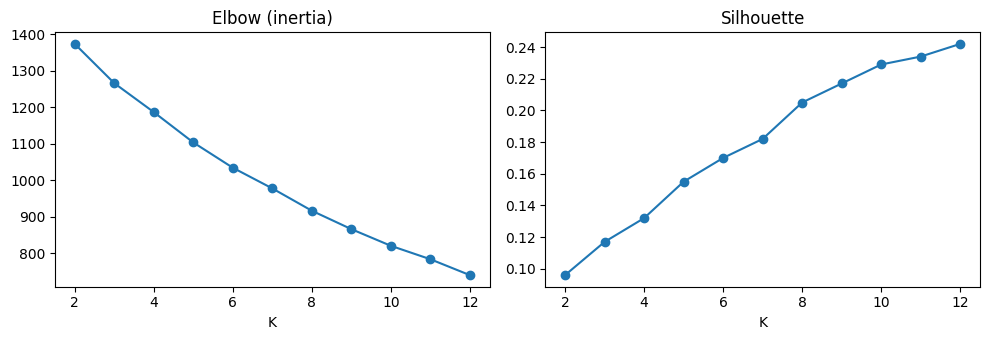

K_BEST (silhouette): 12 | abhi notebook mein K = 8 use ho raha hai

Cluster profile (K = 12 )


,users,view,cart,purchase,avg_price,top_category,top_cat_share
cluster,,,,,,,
0,145,10.15,7.99,2.66,3.41,Nail Care,0.56
1,114,8.51,4.97,1.14,7.70,Nail Care,0.58
2,165,5.28,5.96,1.33,8.44,Beauty & Salon Supplies,0.66
3,162,7.17,5.36,1.43,7.66,Beauty & Salon Supplies,0.49
4,119,9.03,8.05,2.06,5.65,Beauty & Salon Supplies,0.59
5,150,4.89,4.62,1.39,10.86,Nail Care,0.50
6,240,6.73,6.60,1.34,16.85,Beauty & Salon Supplies,0.52
7,206,8.73,7.53,1.71,4.44,Beauty & Salon Supplies,0.53
8,76,13.57,8.03,2.00,4.46,Beauty & Salon Supplies,0.71


In [36]:
# ===== B10: K ka sahi chunao (Silhouette + Elbow) aur cluster ki profile =====
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score

Rm, uix = R_core_real, uix_core_real          # B9 wala hi matrix (Xe isi se bana hai)

rows = []
for K in range(2, 13):
    km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xe)
    rows.append((K, round(km.inertia_, 2), round(silhouette_score(Xe, km.labels_), 3)))
k_tbl = pd.DataFrame(rows, columns=['K', 'inertia', 'silhouette'])
display(k_tbl)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(k_tbl.K, k_tbl.inertia, marker='o');    ax[0].set_title('Elbow (inertia)'); ax[0].set_xlabel('K')
ax[1].plot(k_tbl.K, k_tbl.silhouette, marker='o'); ax[1].set_title('Silhouette');      ax[1].set_xlabel('K')
plt.tight_layout(); plt.show()

# K=2 aksar sirf "active vs inactive" hota hai, isliye 3 se 12 ke beech sab se behtar chunte hain
K_BEST = int(k_tbl[k_tbl.K >= 3].sort_values('silhouette', ascending=False).iloc[0].K)
print('K_BEST (silhouette):', K_BEST, '| abhi notebook mein K = 8 use ho raha hai')


def cluster_profile(K):
    km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xe)
    uid_by_row = np.empty(len(uix), dtype=np.int64)
    for u, i in uix.items():
        uid_by_row[i] = u
    lab_s = pd.Series(km.labels_, index=uid_by_row, name='cluster')

    t = train_core[train_core.user_id.isin(uix)]
    piv = t.pivot_table(index='user_id', columns='event_type', values='product_id',
                        aggfunc='count', fill_value=0)
    for c in ['view', 'cart', 'purchase', 'remove_from_cart']:
        if c not in piv.columns:
            piv[c] = 0
    piv['avg_price'] = t.groupby('user_id')['price'].mean()
    piv = piv.join(lab_s)

    prof = piv.groupby('cluster').agg(users=('view', 'size'), view=('view', 'mean'),
                                      cart=('cart', 'mean'), purchase=('purchase', 'mean'),
                                      avg_price=('avg_price', 'mean')).round(2)
    cats = t.merge(lab_s, left_on='user_id', right_index=True)
    share = pd.crosstab(cats['cluster'], cats['main_category'], normalize='index').round(2)
    prof['top_category'] = share.idxmax(axis=1)
    prof['top_cat_share'] = share.max(axis=1)
    return prof

print('\nCluster profile (K =', K_BEST, ')')
display(cluster_profile(K_BEST))

In [37]:
print("Cluster Profile (K = 8)")
display(cluster_profile(8))



Cluster Profile (K = 8)


,users,view,cart,purchase,avg_price,top_category,top_cat_share
cluster,,,,,,,
0,410,7.19,6.77,1.61,13.52,Beauty & Salon Supplies,0.55
1,173,5.51,5.84,1.29,8.34,Beauty & Salon Supplies,0.66
2,200,9.91,6.35,1.72,6.97,Nail Care,0.67
3,160,10.92,8.26,2.80,3.49,Nail Care,0.55
4,210,7.20,4.66,1.35,13.04,Beauty & Salon Supplies,0.51
5,262,9.36,6.67,1.50,4.66,Beauty & Salon Supplies,0.61
6,221,6.35,6.00,1.48,6.95,Beauty & Salon Supplies,0.46
7,80,8.64,3.00,0.60,13.83,Beauty & Salon Supplies,0.69


,K,inertia,silhouette
0,13,707.81,0.250
1,14,678.18,0.256
2,15,652.35,0.260
3,16,626.68,0.266
4,17,609.92,0.264
5,18,594.23,0.265
6,19,579.82,0.263
7,20,563.24,0.264


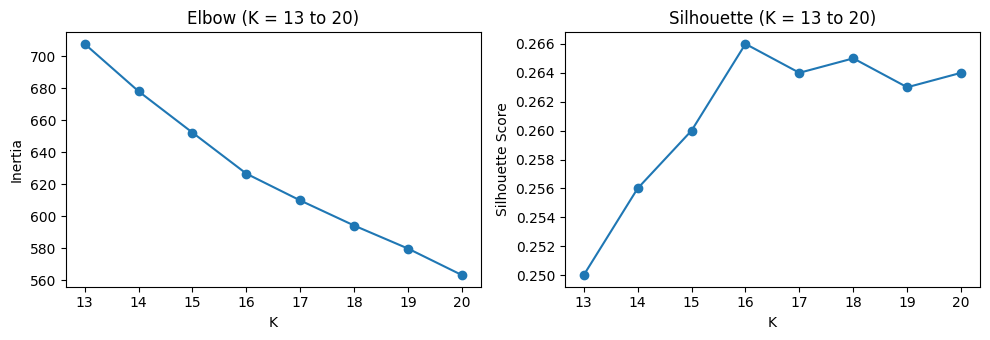

,K,inertia,silhouette
14,16,626.68,0.266
16,18,594.23,0.265
18,20,563.24,0.264
15,17,609.92,0.264
17,19,579.82,0.263
13,15,652.35,0.260
12,14,678.18,0.256
11,13,707.81,0.250
10,12,740.46,0.242
9,11,784.00,0.234


Best K from 2 to 20: 16


In [38]:
# ===== B11: K = 13 to 20 Silhouette Comparison =====

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt

rows = []

for K in range(13, 21):

    km = KMeans(
        n_clusters=K,
        n_init=10,
        random_state=42
    )

    labels = km.fit_predict(Xe)

    score = silhouette_score(Xe, labels)

    rows.append({
        'K': K,
        'inertia': round(km.inertia_, 2),
        'silhouette': round(score, 3)
    })

k_tbl_extended = pd.DataFrame(rows)

display(k_tbl_extended)


# Graphs
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))

ax[0].plot(
    k_tbl_extended['K'],
    k_tbl_extended['inertia'],
    marker='o'
)
ax[0].set_title('Elbow (K = 13 to 20)')
ax[0].set_xlabel('K')
ax[0].set_ylabel('Inertia')

ax[1].plot(
    k_tbl_extended['K'],
    k_tbl_extended['silhouette'],
    marker='o'
)
ax[1].set_title('Silhouette (K = 13 to 20)')
ax[1].set_xlabel('K')
ax[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()


# K = 2 to 20 complete comparison
all_k_results = pd.concat([
    k_tbl[k_tbl['K'] <= 12],
    k_tbl_extended
], ignore_index=True)

display(
    all_k_results.sort_values(
        'silhouette',
        ascending=False
    )
)

print(
    "Best K from 2 to 20:",
    int(all_k_results.loc[
        all_k_results['silhouette'].idxmax(), 'K'
    ])
)

In [39]:
# ===== B11: Hybrid ke weights validation par aazmana (haath se nahi) =====
import itertools

K_USE = 8                                  # agar K=8 hi rakhna ho to K_USE = 8 likh dein
parts['cl'] = make_cluster_pop(K_USE)

users_val = sorted(val_pairs[(val_pairs.source == 'real') & val_pairs.is_warm
                             & val_pairs.user_id.isin(uix)].user_id.unique())
cache = {u: {k: np.asarray(f(u), dtype=float) for k, f in parts.items()} for u in users_val}

keys = ['cf', 'svd', 'cl', 'pop']
grid = [w for w in itertools.product([0, .25, .5, .75, 1], repeat=4) if abs(sum(w) - 1) < 1e-9]

rows = []
for w in grid:
    fn = lambda u, w=w: sum(wk * cache[u][k] for wk, k in zip(w, keys))
    d = evaluate_mode(fn, train_core, uix, val_pairs, mode='discovery')
    r = evaluate_mode(fn, train_core, uix, val_pairs, mode='resurface')
    half = np.arange(len(d)) % 2 == 0                   # users ke do hisse, stability dekhne ke liye
    rows.append({**dict(zip(keys, w)),
                 'hit_new': round(d.hit.mean(), 3), 'ndcg_new': round(d.ndcg.mean(), 3),
                 'ndcg_new_A': round(d.ndcg[half].mean(), 3), 'ndcg_new_B': round(d.ndcg[~half].mean(), 3),
                 'hit_old': round(r.hit.mean(), 3), 'ndcg_old': round(r.ndcg.mean(), 3)})

wtbl = pd.DataFrame(rows).sort_values('ndcg_new', ascending=False).reset_index(drop=True)
print('Top 10 weight combinations (new = sirf nayi cheezein, old = purani cheezein bhi allowed):')
display(wtbl.head(10))
eq = wtbl[(wtbl.cf == .25) & (wtbl.svd == .25) & (wtbl.cl == .25) & (wtbl['pop'] == .25)]
print('Barabar weights (0.25 har ek) ki position:')
display(eq)

Top 10 weight combinations (new = sirf nayi cheezein, old = purani cheezein bhi allowed):


,cf,svd,cl,pop,hit_new,ndcg_new,ndcg_new_A,ndcg_new_B,hit_old,ndcg_old
0,0.25,0.50,0.25,0.00,0.138,0.030,0.034,0.026,0.553,0.220
1,0.25,0.50,0.00,0.25,0.145,0.030,0.035,0.025,0.547,0.213
2,0.00,0.75,0.25,0.00,0.145,0.030,0.034,0.025,0.509,0.178
3,0.25,0.75,0.00,0.00,0.101,0.028,0.031,0.025,0.553,0.227
4,0.25,0.25,0.25,0.25,0.145,0.027,0.032,0.022,0.553,0.181
5,0.00,1.00,0.00,0.00,0.107,0.027,0.032,0.022,0.491,0.183
6,0.00,0.50,0.50,0.00,0.164,0.027,0.032,0.021,0.472,0.156
7,0.25,0.25,0.50,0.00,0.157,0.027,0.033,0.020,0.579,0.193
8,0.00,0.75,0.00,0.25,0.126,0.026,0.032,0.021,0.497,0.172
9,0.50,0.50,0.00,0.00,0.107,0.026,0.028,0.023,0.585,0.237


Barabar weights (0.25 har ek) ki position:


,cf,svd,cl,pop,hit_new,ndcg_new,ndcg_new_A,ndcg_new_B,hit_old,ndcg_old
4,0.25,0.25,0.25,0.25,0.145,0.027,0.032,0.022,0.553,0.181


In [40]:
# ===== COLD-START FINAL TEST (sirf ek baar chalana) =====
d = train_t[train_t.user_id < 990000001]
cnt = (d.pivot_table(index='product_id', columns='event_type', values='user_id',
                     aggfunc='count', fill_value=0).reindex(item_ids).fillna(0))
for c in ['view', 'cart', 'purchase']:
    if c not in cnt.columns:
        cnt[c] = 0
views = (cnt['view'] + cnt['cart']).values.astype(float)
buys  = cnt['purchase'].values.astype(float)
p0   = buys.sum() / (views.sum() + 1e-9)
conv = (buys + 20 * p0) / (views + 20)
nz = lambda x: x / (np.max(x) + 1e-9)
pop7_t = popularity_scores(train_t, days=7, real_only=True)

cands_t = {'Popularity (7d)': pop7_t,
           'Popularity x purchase probability': nz(pop7_t) * nz(conv)}
rows = [summarize(evaluate_cold(v, test_t), n) for n, v in cands_t.items()]
display(pd.DataFrame(rows))

,model,users,hit@10,ci_lo,ci_hi,precision@10,ndcg@10
0,Popularity (7d),234,0.209,0.158,0.261,0.025,0.048
1,Popularity x purchase probability,234,0.188,0.137,0.239,0.023,0.039


In [41]:
# ===== EXTRA CHECK: rolling backtest (kya hybrid ka farq asli hai?) =====
WINDOWS = ['2019-12-08', '2019-12-12', '2019-12-16', '2019-12-20']
HORIZON = pd.Timedelta(days=7)
res_h, res_p = [], []

for c in WINDOWS:
    cut  = pd.Timestamp(c, tz='UTC')
    tr_w = df[df.event_time < cut]
    lat  = df[(df.event_time >= cut) & (df.event_time < cut + HORIZON)]
    pairs = make_pairs(tr_w, lat)

    Rw, _, uixw = build_R(tr_w, real_only=True)
    pop_w = popularity_scores(tr_w, days=7, real_only=True)
    parts_w, _, _ = build_parts(tr_w, Rw, uixw, pop_w)
    hyb_fn = lambda u: sum(w * parts_w[k](u) for k, w in FINAL_W.items())
    pop_fn = parts_w['pop']

    a = evaluate_mode(hyb_fn, tr_w, uixw, pairs, mode='discovery')
    b = evaluate_mode(pop_fn, tr_w, uixw, pairs, mode='discovery')
    for r in (a, b):
        r['user_id'] = r['user_id'].astype(str) + '_' + c   # har window ka user alag ginna
    res_h.append(a); res_p.append(b)
    print(c, '| users:', len(a), '| hybrid hit:', round(a.hit.mean(), 3),
          '| popularity hit:', round(b.hit.mean(), 3))

H, P = pd.concat(res_h), pd.concat(res_p)
print('\nTotal user-windows:', len(H))
for col in ['hit', 'ndcg']:
    d, lo, hi = paired_diff(H, P, col)
    print(f'Hybrid - Popularity ({col}, nayi cheezein): {d} [{lo}, {hi}]',
          '-> asli farq' if (lo > 0 or hi < 0) else '-> farq pakka nahi')

2019-12-08 | users: 120 | hybrid hit: 0.167 | popularity hit: 0.158
2019-12-12 | users: 157 | hybrid hit: 0.159 | popularity hit: 0.102
2019-12-16 | users: 150 | hybrid hit: 0.14 | popularity hit: 0.087
2019-12-20 | users: 129 | hybrid hit: 0.178 | popularity hit: 0.132

Total user-windows: 556
Hybrid - Popularity (hit, nayi cheezein): 0.043 [0.014, 0.072] -> asli farq
Hybrid - Popularity (ndcg, nayi cheezein): 0.011 [0.005, 0.019] -> asli farq


In [42]:
# ===== EXTRA CHECK 2: backtest, har user ek hi baar (overlap ka fix) =====
M = H.merge(P, on='user_id', suffixes=('_h', '_p'))
M['uid'] = M.user_id.str.rsplit('_', n=1).str[0]              # same user in many windows = ONE person
per_user = (M.assign(d_hit=M.hit_h - M.hit_p, d_ndcg=M.ndcg_h - M.ndcg_p)
              .groupby('uid')[['d_hit', 'd_ndcg']].mean())
rng_b = np.random.default_rng(42)
for col in ['d_hit', 'd_ndcg']:
    v = per_user[col].values
    means = rng_b.choice(v, (2000, len(v))).mean(axis=1)
    lo, hi = np.percentile(means, [2.5, 97.5])
    print(f'{col}: {v.mean():.3f} [{lo:.3f}, {hi:.3f}]  users: {len(v)}',
          '-> asli farq' if (lo > 0 or hi < 0) else '-> farq pakka nahi')

d_hit: 0.043 [0.009, 0.076]  users: 377 -> asli farq
d_ndcg: 0.013 [0.004, 0.022]  users: 377 -> asli farq


In [43]:
# ===== FIX A: FINAL MODEL = wahi jo test hua (real users), fit + SAVE + load check =====
import joblib, os, json

OUT = '/kaggle/working/dashboard_export'
os.makedirs(OUT, exist_ok=True)

def _nrm(x):
    s = np.clip(np.asarray(x, dtype=float), 0, None)
    return s / (s.max() + 1e-9)

def fit_final_model(train_df, Rm, uix, pop_vec, weights, n_svd=50, K=8, lam=0.3):
    """build_parts jaisa hi hisaab, lekin seekhe hue models ko object mein rakhta hai taake save ho sakein."""
    pn = pop_vec / (pop_vec.max() + 1e-9)
    S = cosine_similarity(Rm.T, dense_output=False).toarray()
    np.fill_diagonal(S, 0)

    svd_model = TruncatedSVD(n_components=n_svd, random_state=42)
    U = svd_model.fit_transform(Rm)                         # <- SVD yahan seekhta hai

    emb_model = TruncatedSVD(n_components=16, random_state=42)
    Xe_ = normalize(emb_model.fit_transform(Rm))
    km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xe_)   # <- KMeans yahan seekhta hai
    lab = km.labels_

    tr_ = train_df[train_df.user_id.isin(uix)]
    w = tr_.event_type.map(W_POP).values
    ip = tr_.product_id.map(i_idx).values.astype(int)
    uc = lab[tr_.user_id.map(uix).values.astype(int)]
    cp = {}
    for c in range(K):
        v = np.bincount(ip[uc == c], weights=w[uc == c], minlength=len(item_ids))
        cp[c] = v / (v.max() + 1e-9)

    return {'R': Rm, 'S': S, 'U': U, 'V': svd_model.components_, 'lab': lab, 'cp': cp,
            'pn': pn, 'uix': uix, 'item_ids': item_ids, 'weights': weights, 'lam': lam,
            'svd_model': svd_model, 'emb_model': emb_model, 'kmeans': km}

def model_scores(M, u):
    """Sirf saved model se score (dobara training nahi)."""
    i = M['uix'][u]
    tie_ = 1e-6 * M['pn']
    cf  = _nrm(np.asarray(M['R'][i] @ M['S']).ravel() + tie_)
    svd = _nrm(M['U'][i] @ M['V'] + tie_)
    cl  = (1 - M['lam']) * M['cp'][M['lab'][i]] + M['lam'] * M['pn']
    w = M['weights']
    return w['cf'] * cf + w['svd'] * svd + w['cl'] * cl + w['pop'] * M['pn']

# --- wahi setting jo validation, final test aur backtest mein thi: sirf REAL users ---
R_srv, _, uix_srv = build_R(df, real_only=True)
pop_srv = popularity_scores(df, days=7, real_only=True)
M_srv = fit_final_model(df, R_srv, uix_srv, pop_srv, FINAL_W)

joblib.dump(M_srv, f'{OUT}/hybrid_model.joblib', compress=3)
print('Saved:', f'{OUT}/hybrid_model.joblib', '| size MB:', round(os.path.getsize(f'{OUT}/hybrid_model.joblib') / 1e6, 1))

# --- check: load karke wahi recommendations aati hain jo build_parts se aati thin? ---
M_load = joblib.load(f'{OUT}/hybrid_model.joblib')
parts_chk, _, _ = build_parts(df, R_srv, uix_srv, pop_srv)
chk_fn = lambda u: sum(w * parts_chk[k](u) for k, w in FINAL_W.items())

sample = list(uix_srv)[:50]
same = sum(set(topk(model_scores(M_load, u), 10)) == set(topk(np.asarray(chk_fn(u), dtype=float), 10)) for u in sample)
print(f'Saved model == build_parts model: {same}/{len(sample)} users ki top-10 barabar')
print('Seekhe hue objects:', type(M_load['svd_model']).__name__, '|', type(M_load['kmeans']).__name__)

Saved: /kaggle/working/dashboard_export/hybrid_model.joblib | size MB: 6.7
Saved model == build_parts model: 50/50 users ki top-10 barabar
Seekhe hue objects: TruncatedSVD | KMeans


In [44]:
# ===== FIX B: recommend() + export (isi saved model se) + metrics sahi numbers ke saath =====
prod_info = products.set_index('product_id')[['product_name', 'brand', 'main_category', 'price_pkr']]

def recommend(user_id, k=10, only_new=True, model=None):
    """Purana user -> hybrid (saved model). Naya user -> popularity (7 din)."""
    M = M_srv if model is None else model
    if user_id in M['uix']:
        s = model_scores(M, user_id).copy()
        t = df[df.user_id == user_id]
        seen = t['product_id'] if only_new else t[t.event_type == 'purchase']['product_id']
        s[seen.map(i_idx).values] = -np.inf
        kind = 'hybrid (purana user)'
    else:
        s = M['pn'].copy()
        kind = 'popularity (naya user)'
    ids = item_ids[topk(s, k)]
    out = prod_info.loc[ids].reset_index()
    out.insert(0, 'rank', range(1, k + 1))
    print('Model:', kind, '| user:', user_id)
    return out

display(recommend(list(uix_srv)[0]))
display(recommend(123456789))

# har real user ki top-10 (history = sirf khareedi hui hatao, discovery = dekhi hui sab hatao)
g_all = df.groupby('user_id')['product_id'].apply(lambda s: s.map(i_idx).values)
g_buy = df[df.event_type == 'purchase'].groupby('user_id')['product_id'].apply(lambda s: s.map(i_idx).values)
empty = np.array([], dtype=int)

rows = []
for u in uix_srv:
    base = model_scores(M_srv, u)
    for mode, seen in (('history', g_buy.get(u, empty)), ('discovery', g_all.get(u, empty))):
        s = base.copy(); s[seen] = -np.inf
        for rank, ix in enumerate(topk(s, 10), start=1):
            rows.append((u, mode, rank, int(item_ids[ix]), float(base[ix])))
pd.DataFrame(rows, columns=['user_id', 'mode', 'rank', 'product_id', 'score']) \
  .to_csv(f'{OUT}/recommendations_top10.csv', index=False)

# naye users: popularity (7 din). Test par ye "popularity x purchase prob" se behtar nikli.
pop_top = topk(M_srv['pn'], 10)
pd.DataFrame({'rank': range(1, 11), 'product_id': item_ids[pop_top].astype(int),
              'score': M_srv['pn'][pop_top]}).to_csv(f'{OUT}/cold_start_top10.csv', index=False)

final_tbl.to_csv(f'{OUT}/test_results_warm.csv', index=False)

# metrics: numbers haath se nahi, variables se (overlap-fix wala backtest, cell 41 ke per_user se)
cold_test = summarize(evaluate_cold(pop7_t, test_t), 'Popularity (7d)')
rng_m = np.random.default_rng(42)
bt = {}
for col in ['d_hit', 'd_ndcg']:
    v = per_user[col].values
    means = rng_m.choice(v, (2000, len(v))).mean(axis=1)
    lo, hi = np.percentile(means, [2.5, 97.5])
    bt[col] = [round(float(v.mean()), 3), round(float(lo), 3), round(float(hi), 3)]

metrics = {
    'cold_start_test': {'model': 'Popularity (7d)', 'users': int(cold_test['users']),
                        'hit@10': float(cold_test['hit@10']), 'ci': [float(cold_test['ci_lo']), float(cold_test['ci_hi'])]},
    'rolling_backtest_one_row_per_user': {'users': int(len(per_user)),
                        'hit_diff_vs_popularity': bt['d_hit'], 'ndcg_diff_vs_popularity': bt['d_ndcg']},
    'final_model': 'Hybrid: CF 0.25 + SVD(n=50) 0.25 + KMeans clusters(K=8) 0.25 + Popularity(7d) 0.25; trained on real users only',
    'split': 'train < 2019-12-20 | test >= 2019-12-20 | validation 13-19 Dec',
}
json.dump(metrics, open(f'{OUT}/metrics.json', 'w'), indent=2)
print(sorted(os.listdir(OUT)))
print(json.dumps(metrics, indent=2))

Model: hybrid (purana user) | user: 51824526


,rank,product_id,product_name,brand,main_category,price_pkr
0,1,5809910,Grattol Nail Product #9910,grattol,Nail Care,1467
1,2,5833335,Bpw.Style Nail Product #3335,bpw.style,Nail Care,445
2,3,5815662,Generic Beauty Product #5662,unknown,Beauty & Salon Supplies,258
3,4,5833325,Bpw.Style Nail Product #3325,bpw.style,Nail Care,445
4,5,5833326,Bpw.Style Nail Product #3326,bpw.style,Nail Care,445
5,6,5906119,Bpw.Style Nail Product #6119,bpw.style,Nail Care,356
6,7,5700037,Runail Nail Product #0037,runail,Nail Care,112
7,8,5833334,Bpw.Style Nail Product #3334,bpw.style,Nail Care,221
8,9,5854897,Irisk Nail Product #4897,irisk,Nail Care,90
9,10,5802432,Generic Beauty Product #2432,unknown,Beauty & Salon Supplies,90


Model: popularity (naya user) | user: 123456789


,rank,product_id,product_name,brand,main_category,price_pkr
0,1,5809910,Grattol Nail Product #9910,grattol,Nail Care,1467
1,2,5809912,Grattol Nail Product #9912,grattol,Nail Care,1467
2,3,5815662,Generic Beauty Product #5662,unknown,Beauty & Salon Supplies,258
3,4,5802432,Generic Beauty Product #2432,unknown,Beauty & Salon Supplies,90
4,5,5561044,Generic Beauty Product #1044,unknown,Beauty & Salon Supplies,840
5,6,5854897,Irisk Nail Product #4897,irisk,Nail Care,90
6,7,5751422,UNO Nail Product #1422,uno,Nail Care,3066
7,8,5700037,Runail Nail Product #0037,runail,Nail Care,112
8,9,5809911,Grattol Nail Product #9911,grattol,Nail Care,1467
9,10,5686925,Generic Beauty Product #6925,unknown,Beauty & Salon Supplies,98


['cold_start_top10.csv', 'hybrid_model.joblib', 'metrics.json', 'recommendations_top10.csv', 'test_results_warm.csv']
{
  "cold_start_test": {
    "model": "Popularity (7d)",
    "users": 234,
    "hit@10": 0.209,
    "ci": [
      0.158,
      0.261
    ]
  },
  "rolling_backtest_one_row_per_user": {
    "users": 377,
    "hit_diff_vs_popularity": [
      0.043,
      0.009,
      0.076
    ],
    "ndcg_diff_vs_popularity": [
      0.013,
      0.004,
      0.022
    ]
  },
  "final_model": "Hybrid: CF 0.25 + SVD(n=50) 0.25 + KMeans clusters(K=8) 0.25 + Popularity(7d) 0.25; trained on real users only",
  "split": "train < 2019-12-20 | test >= 2019-12-20 | validation 13-19 Dec"
}


In [45]:
# ===== CHECK 3: SVD n=200 ka backtest (final test ko haath nahi lagata) =====
WINDOWS3 = ['2019-12-06', '2019-12-09', '2019-12-12', '2019-12-16']
HORIZON3 = pd.Timedelta(days=7)
long_rows = []

def svd_fn(Rm, uix, pop_vec, n):
    pn_ = pop_vec / (pop_vec.max() + 1e-9)
    tie_ = 1e-6 * pn_
    m = TruncatedSVD(n_components=n, random_state=42)
    U = m.fit_transform(Rm)
    V = m.components_
    return lambda u: U[uix[u]] @ V + tie_

for c in WINDOWS3:
    cut = pd.Timestamp(c, tz='UTC')
    end = min(cut + HORIZON3, CUTOFF)            # kabhi 20 Dec (test) tak nahi jata
    tr_w = df[df.event_time < cut]
    lat  = df[(df.event_time >= cut) & (df.event_time < end)]
    pairs = make_pairs(tr_w, lat)

    Rw, _, uixw = build_R(tr_w, real_only=True)
    pop_w = popularity_scores(tr_w, days=7, real_only=True)
    parts_w, _, svd50_w = build_parts(tr_w, Rw, uixw, pop_w)
    models_w = {
        'Popularity (7d)': parts_w['pop'],
        'SVD n=50':        svd50_w,
        'SVD n=200':       svd_fn(Rw, uixw, pop_w, 200),
        'Hybrid (FINAL)':  (lambda u, pw=parts_w: sum(w * pw[k](u) for k, w in FINAL_W.items())),
    }
    n_users = 0
    for mode in ['resurface', 'discovery']:
        for name, fn in models_w.items():
            r = evaluate_mode(fn, tr_w, uixw, pairs, mode=mode)
            n_users = len(r)
            r['window'], r['mode'], r['model'] = c, mode, name
            long_rows.append(r)
    print(c, '| eval:', cut.date(), '->', (end - pd.Timedelta(days=1)).date(), '| users:', n_users)

L3 = pd.concat(long_rows, ignore_index=True)

print('\nHit@10 har window mein (purani cheezein allowed):')
display(L3[L3['mode'] == 'resurface'].groupby(['window', 'model'])['hit'].mean().unstack().round(3))

rng3 = np.random.default_rng(42)
out = []
for mode in ['resurface', 'discovery']:
    pu = L3[L3['mode'] == mode].groupby(['model', 'user_id'])[['hit', 'ndcg']].mean()   # har user ek hi baar
    print('\nMODE:', mode)
    display(pu.groupby('model').agg(users=('hit', 'size'), hit=('hit', 'mean'), ndcg=('ndcg', 'mean')).round(3))
    for a, b in [('SVD n=200', 'Popularity (7d)'), ('SVD n=200', 'Hybrid (FINAL)'), ('Hybrid (FINAL)', 'Popularity (7d)')]:
        A, B = pu.loc[a], pu.loc[b]
        idx = A.index.intersection(B.index)
        for col in ['hit', 'ndcg']:
            d = (A.loc[idx, col] - B.loc[idx, col]).values
            means = rng3.choice(d, (2000, len(d))).mean(axis=1)
            lo, hi = np.percentile(means, [2.5, 97.5])
            out.append((mode, f'{a} - {b}', col, len(d), round(d.mean(), 3), round(lo, 3), round(hi, 3),
                        'asli farq' if (lo > 0 or hi < 0) else 'farq pakka nahi'))
display(pd.DataFrame(out, columns=['mode', 'muqabla', 'metric', 'users', 'farq', 'ci_lo', 'ci_hi', 'natija']))

2019-12-06 | eval: 2019-12-06 -> 2019-12-12 | users: 99
2019-12-09 | eval: 2019-12-09 -> 2019-12-15 | users: 138
2019-12-12 | eval: 2019-12-12 -> 2019-12-18 | users: 157
2019-12-16 | eval: 2019-12-16 -> 2019-12-19 | users: 116

Hit@10 har window mein (purani cheezein allowed):


model,Hybrid (FINAL),Popularity (7d),SVD n=200,SVD n=50
window,,,,
2019-12-06,0.525,0.283,0.596,0.434
2019-12-09,0.522,0.246,0.638,0.507
2019-12-12,0.567,0.229,0.631,0.561
2019-12-16,0.560,0.198,0.638,0.543



MODE: resurface


,users,hit,ndcg
model,,,
Hybrid (FINAL),301,0.556,0.207
Popularity (7d),301,0.231,0.052
SVD n=200,301,0.648,0.318
SVD n=50,301,0.531,0.206



MODE: discovery


,users,hit,ndcg
model,,,
Hybrid (FINAL),301,0.152,0.032
Popularity (7d),301,0.130,0.021
SVD n=200,301,0.091,0.020
SVD n=50,301,0.102,0.027


,mode,muqabla,metric,users,farq,ci_lo,ci_hi,natija
0,resurface,SVD n=200 - Popularity (7d),hit,301,0.417,0.354,0.478,asli farq
1,resurface,SVD n=200 - Popularity (7d),ndcg,301,0.266,0.232,0.302,asli farq
2,resurface,SVD n=200 - Hybrid (FINAL),hit,301,0.092,0.055,0.130,asli farq
3,resurface,SVD n=200 - Hybrid (FINAL),ndcg,301,0.111,0.086,0.136,asli farq
4,resurface,Hybrid (FINAL) - Popularity (7d),hit,301,0.325,0.264,0.383,asli farq
5,resurface,Hybrid (FINAL) - Popularity (7d),ndcg,301,0.155,0.132,0.179,asli farq
6,discovery,SVD n=200 - Popularity (7d),hit,301,-0.039,-0.084,0.007,farq pakka nahi
7,discovery,SVD n=200 - Popularity (7d),ndcg,301,-0.002,-0.013,0.011,farq pakka nahi
8,discovery,SVD n=200 - Hybrid (FINAL),hit,301,-0.061,-0.098,-0.029,asli farq
9,discovery,SVD n=200 - Hybrid (FINAL),ndcg,301,-0.012,-0.022,-0.002,asli farq


In [46]:
# ===== SYN-1: Synthetic segment ko validation par aazmana (alag model, alag popularity) =====
SYN_MIN = 990000001

def evaluate_seg(score_fn, train_df, uix, pairs, source, k=10, mode='discovery'):
    """evaluate_mode jaisa hi, bas source ('real' ya 'synthetic') chunne ki sahulat ke saath."""
    p = pairs[(pairs.source == source) & pairs.is_warm & pairs.user_id.isin(uix)]
    src = train_df if mode == 'discovery' else train_df[train_df.event_type == 'purchase']
    seen = src.groupby('user_id')['product_id'].apply(lambda s: s.map(i_idx).values)
    disc = 1 / np.log2(np.arange(2, k + 2))
    out = []
    for u, g in p.groupby('user_id'):
        s = np.asarray(score_fn(u), dtype=float).copy()
        b = seen.get(u)
        if b is not None:
            s[b] = -np.inf
        rec = topk(s, k)
        truth = set(g['product_id'].map(i_idx))
        hit = np.array([r in truth for r in rec])
        ideal = disc[:min(len(truth), k)].sum()
        out.append((u, int(hit.any()), hit.sum() / k, (hit * disc).sum() / ideal))
    return pd.DataFrame(out, columns=['user_id', 'hit', 'precision', 'ndcg'])

tr_syn = train_core[train_core.user_id >= SYN_MIN]
R_syn_core, _, uix_syn_core = build_R(tr_syn)
pop_syn_core = popularity_scores(tr_syn, days=7)
print('Synthetic users in train_core matrix:', R_syn_core.shape)

parts_s, cf_s, svd_s = build_parts(tr_syn, R_syn_core, uix_syn_core, pop_syn_core)
hyb_s = lambda u: sum(w * parts_s[k](u) for k, w in FINAL_W.items())

models_s = {
    'Popularity (synthetic, 7d)':            parts_s['pop'],
    'Popularity (REAL, 7d) [galat segment]': (lambda u: pop_core_7_real),
    'CF':                                    cf_s,
    'SVD n=50':                              svd_s,
    'Hybrid (synthetic)':                    hyb_s,
}
rows = []
for name, fn in models_s.items():
    for mode in ['resurface', 'discovery']:
        r = evaluate_seg(fn, train_core, uix_syn_core, val_pairs, 'synthetic', mode=mode)
        s = summarize(r, name)
        rows.append({'model': name, 'mode': mode, 'users': s['users'], 'hit@10': s['hit@10'],
                     'ci_lo': s['ci_lo'], 'ci_hi': s['ci_hi'], 'ndcg@10': s['ndcg@10']})
display(pd.DataFrame(rows).sort_values(['mode', 'ndcg@10'], ascending=[True, False]).reset_index(drop=True))

Synthetic users in train_core matrix: (793, 1885)


,model,mode,users,hit@10,ci_lo,ci_hi,ndcg@10
0,Hybrid (synthetic),discovery,287,0.310,0.254,0.366,0.148
1,CF,discovery,287,0.258,0.209,0.310,0.122
2,"Popularity (synthetic, 7d)",discovery,287,0.244,0.192,0.296,0.105
3,SVD n=50,discovery,287,0.101,0.066,0.136,0.046
4,"Popularity (REAL, 7d) [galat segment]",discovery,287,0.000,0.000,0.000,0.000
5,Hybrid (synthetic),resurface,287,0.362,0.303,0.418,0.175
6,CF,resurface,287,0.317,0.261,0.369,0.137
7,"Popularity (synthetic, 7d)",resurface,287,0.310,0.258,0.362,0.130
8,SVD n=50,resurface,287,0.213,0.164,0.261,0.099
9,"Popularity (REAL, 7d) [galat segment]",resurface,287,0.000,0.000,0.000,0.000


In [47]:
# ===== SYN-2: Synthetic segment ka alag model + dashboard export =====

# ---- 1) Synthetic users par alag model fit + save (real wala M_srv waisa hi rehta hai) ----
df_syn = df[df.user_id >= SYN_MIN]
R_syn, _, uix_syn = build_R(df_syn)
pop_syn = popularity_scores(df_syn, days=7)
M_syn = fit_final_model(df_syn, R_syn, uix_syn, pop_syn, FINAL_W)

joblib.dump(M_syn, f'{OUT}/hybrid_model_synthetic.joblib', compress=3)
print('Saved synthetic model | users:', R_syn.shape[0], '| size MB:',
      round(os.path.getsize(f'{OUT}/hybrid_model_synthetic.joblib') / 1e6, 1))

# ---- 2) Ek hi recommend function: user_id dekh kar sahi model chunta hai ----
def recommend_any(user_id, k=10, only_new=True, segment=None):
    is_syn = (user_id >= SYN_MIN) if segment is None else (segment == 'synthetic')
    return recommend(user_id, k=k, only_new=only_new, model=M_syn if is_syn else M_srv)

display(recommend_any(list(uix_srv)[0]))                  # real user
display(recommend_any(list(uix_syn)[0]))                  # synthetic user
display(recommend_any(123456789, segment='synthetic'))    # naya synthetic user

# ---- 3) Export: real + synthetic ek CSV mein, 'segment' column ke saath ----
g_all_s = df_syn.groupby('user_id')['product_id'].apply(lambda s: s.map(i_idx).values)
g_buy_s = df_syn[df_syn.event_type == 'purchase'].groupby('user_id')['product_id'].apply(lambda s: s.map(i_idx).values)
empty = np.array([], dtype=int)

rows_s = []
for u in uix_syn:
    base = model_scores(M_syn, u)
    for mode, seen in (('history', g_buy_s.get(u, empty)), ('discovery', g_all_s.get(u, empty))):
        s = base.copy(); s[seen] = -np.inf
        for rank, ix in enumerate(topk(s, 10), start=1):
            rows_s.append((u, mode, rank, int(item_ids[ix]), float(base[ix])))
rec_syn = pd.DataFrame(rows_s, columns=['user_id', 'mode', 'rank', 'product_id', 'score'])
rec_syn['segment'] = 'synthetic'

rec_real = pd.read_csv(f'{OUT}/recommendations_top10.csv')
rec_real['segment'] = 'real'
pd.concat([rec_real, rec_syn], ignore_index=True).to_csv(f'{OUT}/recommendations_top10_all.csv', index=False)

# synthetic naye users ke liye cold-start (synthetic popularity)
pop_top_s = topk(M_syn['pn'], 10)
pd.DataFrame({'rank': range(1, 11), 'product_id': item_ids[pop_top_s].astype(int),
              'score': M_syn['pn'][pop_top_s]}).to_csv(f'{OUT}/cold_start_top10_synthetic.csv', index=False)

# ---- 4) metrics.json mein synthetic ka alag, saaf label wala block ----
r_syn = evaluate_seg(hyb_s, train_core, uix_syn_core, val_pairs, 'synthetic', mode='discovery')
s_syn = summarize(r_syn, 'Hybrid (synthetic)')
metrics['synthetic_segment_validation'] = {
    'note': 'DEMO ONLY: synthetic data par validation; real performance ka claim nahi.',
    'users': int(s_syn['users']), 'hit@10_new_items': float(s_syn['hit@10']),
    'ci': [float(s_syn['ci_lo']), float(s_syn['ci_hi'])],
    'model': 'Hybrid trained on synthetic users only (alag joblib)',
}
json.dump(metrics, open(f'{OUT}/metrics.json', 'w'), indent=2)

# ---- 5) Check: saved model load karke wahi top-10 aati hai? ----
M_chk = joblib.load(f'{OUT}/hybrid_model_synthetic.joblib')
sample = list(uix_syn)[:50]
same = sum(set(topk(model_scores(M_chk, u), 10)) == set(topk(model_scores(M_syn, u), 10)) for u in sample)
print(f'Saved synthetic model check: {same}/{len(sample)} users ki top-10 barabar')
print(sorted(os.listdir(OUT)))

Saved synthetic model | users: 800 | size MB: 1.9
Model: hybrid (purana user) | user: 51824526


,rank,product_id,product_name,brand,main_category,price_pkr
0,1,5809910,Grattol Nail Product #9910,grattol,Nail Care,1467
1,2,5833335,Bpw.Style Nail Product #3335,bpw.style,Nail Care,445
2,3,5815662,Generic Beauty Product #5662,unknown,Beauty & Salon Supplies,258
3,4,5833325,Bpw.Style Nail Product #3325,bpw.style,Nail Care,445
4,5,5833326,Bpw.Style Nail Product #3326,bpw.style,Nail Care,445
5,6,5906119,Bpw.Style Nail Product #6119,bpw.style,Nail Care,356
6,7,5700037,Runail Nail Product #0037,runail,Nail Care,112
7,8,5833334,Bpw.Style Nail Product #3334,bpw.style,Nail Care,221
8,9,5854897,Irisk Nail Product #4897,irisk,Nail Care,90
9,10,5802432,Generic Beauty Product #2432,unknown,Beauty & Salon Supplies,90


Model: hybrid (purana user) | user: 990000001


,rank,product_id,product_name,brand,main_category,price_pkr
0,1,9000040,SG Sports T-Shirt,sg,Sports,4561
1,2,9000002,Yonex Tennis Racket,yonex,Sports,16870
2,3,9000001,Reebok Running Shoes,reebok,Sports,32376
3,4,9000050,Yonex Football,yonex,Sports,5113
4,5,9000152,H&M Handbag,h&m,Fashion,33474
5,6,9000045,Puma Running Shoes,puma,Sports,24786
6,7,9000020,Yonex Sports Water Bottle,yonex,Sports,1784
7,8,9000200,Lock&Lock Electric Kettle,lock&lock,Home & Kitchen,5790
8,9,9000011,Nike Cricket Bat,nike,Sports,30061
9,10,9000100,Oppo Tablet,oppo,Electronics,45853


Model: popularity (naya user) | user: 123456789


,rank,product_id,product_name,brand,main_category,price_pkr
0,1,9000005,Nike Training Jacket,nike,Sports,16324
1,2,9000110,Logitech Tablet,logitech,Electronics,107884
2,3,9000152,H&M Handbag,h&m,Fashion,33474
3,4,9000040,SG Sports T-Shirt,sg,Sports,4561
4,5,9000030,Reebok Gym Gloves,reebok,Sports,3808
5,6,9000200,Lock&Lock Electric Kettle,lock&lock,Home & Kitchen,5790
6,7,9000146,Aldo Hoodie,aldo,Fashion,11886
7,8,9000100,Oppo Tablet,oppo,Electronics,45853
8,9,9000002,Yonex Tennis Racket,yonex,Sports,16870
9,10,9000188,Pyrex Blender,pyrex,Home & Kitchen,20874


Saved synthetic model check: 50/50 users ki top-10 barabar
['cold_start_top10.csv', 'cold_start_top10_synthetic.csv', 'hybrid_model.joblib', 'hybrid_model_synthetic.joblib', 'metrics.json', 'recommendations_top10.csv', 'recommendations_top10_all.csv', 'test_results_warm.csv']


In [48]:
products[['product_id', 'product_name', 'brand', 'main_category', 'price_pkr']] \
    .to_csv(f'{OUT}/products.csv', index=False)
print(sorted(os.listdir(OUT)))

['cold_start_top10.csv', 'cold_start_top10_synthetic.csv', 'hybrid_model.joblib', 'hybrid_model_synthetic.joblib', 'metrics.json', 'products.csv', 'recommendations_top10.csv', 'recommendations_top10_all.csv', 'test_results_warm.csv']
